<a href="https://colab.research.google.com/github/kanishkaidk/SNM_research_paper/blob/main/SNM_LLM_link_prediction_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Where do LLMs help temporal link prediction? A controlled study of history format, order and scale
**Course project: Social Networking and Mining (IGDTUW).** Dataset: DTGB / ICEWS1819 (dynamic text-attributed graph). One notebook, about 3 hours on a free Colab T4. **Run every cell from the top; if Colab disconnects, reconnect and press Run all again. Finished conditions are loaded from Drive, only missing work is redone.**

**Research question.** An LLM is shown a source entity's recent events and asked "will it interact with this candidate next?". (RQ1) Does it beat simple count/recency/co-occurrence heuristics, and *where* (repeat links vs brand-new links)? (RQ2) Do the format, order and timestamps of the history in the prompt matter? (RQ3) Does model size matter? (RQ4) Is the LLM complementary to heuristics (hybrid)?

**What the 500-query validation pilot already told us (design frozen from it; this notebook runs on the untouched TEST split):**
* order of the history does not matter (3B: +0.007, equivalent within +-0.03); the history itself helps a lot at 3B (+0.145) and little at 1.5B (+0.04);
* removing the "N time-steps ago" numbers *improved* 3B (0.496 -> 0.553): raw time numbers distract the model;
* the LLM adds nothing on repeat links but adds a lot on **new links** when combined with heuristics (+0.166, 99 queries) -> this study uses a stratified sample so new links get enough queries;
* hidden-name prompts with raw ids were contaminated (id order carries popularity); we use randomly permuted ids as the control.

**Mistakes from earlier versions that this notebook avoids:** random negatives drawn from future targets (leak); no no-history control; tuning on the test split; query set silently changing between runs (scores are now keyed by a hash of the queries); comparing the fast and slow scorer without a real check; GPU offloading to CPU (models are forced onto the GPU); one wording only; reporting only overall MRR (we report repeat / new / population-weighted).

In [ ]:
# 1. setup  (needs a GPU runtime: Runtime > Change runtime type > T4)
!pip -q install -U transformers accelerate
import os, sys, gc, json, time, math, random, copy, hashlib, shutil, warnings
import numpy as np, pandas as pd
from collections import defaultdict
warnings.filterwarnings('ignore')
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception as e: print('Drive not mounted here:', e)

Mounted at /content/drive


In [ ]:
# 2. CONFIG  (the only cell you may edit)
DATA_ROOT = '/content/drive/MyDrive/DyLink_Datasets'
DATASET   = 'ICEWS1819'
RUN_ID    = 'final_v1'                  # everything is saved in OUT_DIR; change RUN_ID to start a completely fresh run
OUT_DIR   = f'/content/drive/MyDrive/link_pred_runs/{RUN_ID}'
EVAL_SPLIT = 'test'                     # design was frozen on the validation pilot; final numbers come from the untouched test split
SEED = 42
N_PER_STRATUM = 300                     # queries per stratum (repeat links / new links) -> 600 test queries in total
N_VAL_PER_STRATUM = 150                 # separate VALIDATION queries (earlier in time): used only to fit the hybrid, which is then frozen. 0 = no frozen hybrid
N_CAND, N_HIST_NEG, ACTIVE_WINDOW, MAX_WORDS = 20, 6, 2000, 25    # 1 true + 19 negatives (6 history, up to 6 active, rest random)
N_HIST_EVENTS = 15                      # events shown in the raw-event prompts
DIGEST_WINDOW, DIGEST_K = 50, 10        # digest prompt: the source's last 50 events summarised as its top-10 partners with counts
EQ_MARGIN = 0.03                        # equivalence margin (MRR), fixed from the pilot (about 20% of the 3B history effect)
BOOT_B = 2000
BUDGET_MIN = 170                        # a stage is skipped if it would START after this many minutes (resume later to finish it)
IS_COLAB = os.path.exists('/content')

Q3, Q15, Q05 = 'Qwen/Qwen2.5-3B-Instruct', 'Qwen/Qwen2.5-1.5B-Instruct', 'Qwen/Qwen2.5-0.5B-Instruct'
PHI = 'microsoft/Phi-3.5-mini-instruct'
SMALL = ['none', 'nt_recent_first', 'nt_oldest_first', 'digest', 'time_recent_first']
STAGES = [   # in priority order. cond names: none | stats | digest | {time|nt}_{recent_first|oldest_first|shufK} | perm_<cond> (ids randomly permuted)
  dict(name='A: 3B core',        model=Q3,  label='3B',     four_bit=False, enabled=True,
       conds=['none', 'stats', 'nt_recent_first', 'nt_oldest_first', 'time_recent_first', 'time_oldest_first', 'digest', 'digest15']),
  dict(name='B: 3B seeds + controls', model=Q3, label='3B', four_bit=False, enabled=True,
       conds=['nt_shuf0', 'nt_shuf1', 'nt_shuf2', 'perm_none', 'perm_nt_recent_first'], position=True),
  dict(name='C: 1.5B',           model=Q15, label='1.5B',   four_bit=False, enabled=True,  conds=SMALL),
  dict(name='D: 0.5B',           model=Q05, label='0.5B',   four_bit=False, enabled=True,  conds=SMALL),
  dict(name='E: Phi-3.5-mini (other family)', model=PHI, label='Phi3.5', four_bit=False, enabled=True,
       conds=['none', 'nt_recent_first', 'nt_oldest_first', 'digest']),
  dict(name='F: Qwen2.5-7B, 4-bit (optional, slow; needs bitsandbytes)', model='Qwen/Qwen2.5-7B-Instruct', label='7B', four_bit=True, enabled=False,
       conds=['none', 'nt_recent_first', 'nt_oldest_first']),
]
MODEL_SIZE_B = {'0.5B': 0.5, '1.5B': 1.5, '3B': 3.1, 'Phi3.5': 3.8, '7B': 7.6}
os.makedirs(OUT_DIR, exist_ok=True)
for sub in ('figs', 'tables', 'scores'): os.makedirs(f'{OUT_DIR}/{sub}', exist_ok=True)
T_START = time.time()
elapsed_min = lambda: (time.time() - T_START) / 60
print('outputs go to', OUT_DIR)

outputs go to /content/drive/MyDrive/link_pred_runs/final_v1


## 3. Data, chronological split, per-source history index

In [ ]:
# 3. load data (about 1 minute for 1.1 million edges)
d = f'{DATA_ROOT}/{DATASET}'
edges = pd.read_csv(f'{d}/edge_list.csv', usecols=lambda c: c in ('u', 'r', 'i', 'ts'))
ent, rel = pd.read_csv(f'{d}/entity_text.csv'), pd.read_csv(f'{d}/relation_text.csv')
assert {'u', 'r', 'i', 'ts'} <= set(edges.columns), list(edges.columns)

def make_text_map(df):
    id_col = next((c for c in df.columns if str(c).lower() in ('id', 'entity_id', 'relation_id', 'e_id', 'r_id', 'idx', 'index', 'u', 'i', 'r')), df.columns[0])
    other = [c for c in df.columns if c != id_col and not str(c).startswith('Unnamed')]
    return dict(zip(df[id_col], df[other].fillna('').astype(str).agg(' | '.join, axis=1)))
ent_text, rel_text = make_text_map(ent), make_text_map(rel)

edges = edges.sort_values('ts', kind='stable').reset_index(drop=True)          # ties keep file order
E_u, E_i, E_r, E_ts = (edges[c].values.astype(np.int64) for c in ('u', 'i', 'r', 'ts'))
n = len(edges)
# split on TIMESTAMP boundaries (no timestamp is shared between two splits)
tr_ts, va_ts = E_ts[int(0.70 * n)], E_ts[int(0.85 * n)]
split = np.where(E_ts < tr_ts, 0, np.where(E_ts < va_ts, 1, 2))
train_m, val_m, test_m = split == 0, split == 1, split == 2
print(f'edges {n:,} | train {train_m.sum():,} (ts < {tr_ts}) | val {val_m.sum():,} | test {test_m.sum():,} (ts >= {va_ts}) | distinct timestamps {len(np.unique(E_ts))}')

# per-source history index: arrays sorted by (source, time); a query only ever reads rows STRICTLY BEFORE its timestamp
order = np.lexsort((E_ts, E_u))                                                  # stable: ties keep file order
SU, SI, SR, STS = E_u[order], E_i[order], E_r[order], E_ts[order]
uq, first_idx = np.unique(SU, return_index=True)
src_lo = dict(zip(uq.tolist(), first_idx.tolist())); src_hi = dict(zip(uq.tolist(), np.r_[first_idx[1:], len(SU)].tolist()))
src_first_ts = dict(zip(uq.tolist(), STS[first_idx].tolist()))

def hist_end(u, ts):                                                             # index one past the last event with time < ts
    lo, hi = src_lo[u], src_hi[u]
    return lo + int(np.searchsorted(STS[lo:hi], ts, side='left'))
def last_events(u, ts, m):                                                       # last m events before ts, chronological
    h = hist_end(u, ts); a = max(src_lo[u], h - m)
    return list(zip(STS[a:h].tolist(), SI[a:h].tolist(), SR[a:h].tolist()))

train_targets = np.unique(E_i[train_m]); known_set = set(train_targets.tolist())
pop_train = pd.Series(E_i[train_m]).value_counts().to_dict()
TAU = 0.1 * (E_ts[train_m].max() - E_ts[train_m].min())                          # decay constant from the TRAIN period only
print('known (train) targets:', len(known_set), '| train sources:', len(np.unique(E_u[train_m])))

edges 1,100,071 | train 769,599 (ts < 512) | val 164,516 | test 165,956 (ts >= 623) | distinct timestamps 730
known (train) targets: 22107 | train sources: 23301


## 4. Stratified query sampling and candidate sets (saved once, re-loaded after a disconnect)

In [ ]:
# 4. queries: 1 true + 19 negatives. Stratified: N_PER_STRATUM repeat-link queries and N_PER_STRATUM new-link queries.
# 'repeat' = the true target already appeared in the source's own past. It is an ANALYSIS LABEL (uses the answer); no method ever sees it.
pf = pd.DataFrame(dict(u=E_u, i=E_i, ts=E_ts)).groupby(['u', 'i'])['ts'].min().rename('pair_first_ts').reset_index()
def split_pool(split):
    ev = pd.DataFrame(dict(u=E_u, i=E_i, ts=E_ts))[{'val': val_m, 'test': test_m}[split]].reset_index(drop=True).merge(pf, on=['u', 'i'], how='left')
    ev['repeat'] = ev['pair_first_ts'] < ev['ts']
    ev['ok'] = ev['i'].isin(known_set) & ev['u'].map(src_first_ts).lt(ev['ts'])      # known (train) target and the source has at least one earlier event
    pool = ev[ev['ok']]; return ev, pool, float(pool['repeat'].mean())                # last value: population share of repeat links (weights the overall MRR)
ev, pool, P_REP = split_pool(EVAL_SPLIT)
print(f'eligible {EVAL_SPLIT} edges: {len(pool):,} of {len(ev):,} | repeat share in population: {P_REP:.3f}')

CODE_T = {'true': 0, 'hist': 1, 'active': 2, 'random': 3}
G_i, G_ts = E_i, E_ts                                                            # global time-sorted arrays (for the 'active' negatives)
QVER = 'v2'                                                                      # bump when the sampling code changes: old cached query files are then ignored

def make_candidates(q):
    rng = random.Random(SEED * 1_000_003 + q['id'])                              # per-query generator: independent of N and of query order
    u, ts, true_i = q['u'], q['ts'], q['true']
    lo, h = src_lo[u], hist_end(u, ts)
    seen_all = set(np.unique(SI[lo:h]).tolist())
    chosen = {}
    hh = sorted((seen_all & known_set) - {true_i}); rng.shuffle(hh)                # history negatives must also be TRAIN-period (known) targets
    for c in hh[:N_HIST_NEG]: chosen[c] = 'hist'
    g = int(np.searchsorted(G_ts, ts, side='left'))
    act = set(np.intersect1d(np.unique(G_i[max(0, g - ACTIVE_WINDOW):g]), train_targets).tolist()) - seen_all - {true_i} - set(chosen)
    act = sorted(act); rng.shuffle(act)
    for c in act[:max(0, N_CAND - 1 - len(chosen) - 7)]: chosen[c] = 'active'
    while len(chosen) < N_CAND - 1:
        c = int(train_targets[rng.randrange(len(train_targets))])
        if c != true_i and c not in chosen: chosen[c] = 'random'
    pairs = list(chosen.items()) + [(true_i, 'true')]; rng.shuffle(pairs)
    return [int(p[0]) for p in pairs], [p[1] for p in pairs]

def repair_query(q):                                   # replace any non-train candidate (only 'hist' negatives can be affected) by a valid history negative
    bad = [j for j, c in enumerate(q['cands']) if c not in known_set]
    if not bad: return []
    assert all(q['types'][j] == 'hist' for j in bad), 'unexpected: a non-history candidate is not a known target'
    rng = random.Random(SEED * 1_000_003 + q['id'] + 777); lo, h = src_lo[q['u']], hist_end(q['u'], q['ts'])
    spare = sorted((set(np.unique(SI[lo:h]).tolist()) & known_set) - set(q['cands']) - {q['true']}); rng.shuffle(spare)
    for j in bad:
        if spare: q['cands'][j], q['types'][j] = spare.pop(), 'hist'
        else:
            while True:
                c = int(train_targets[rng.randrange(len(train_targets))])
                if c != q['true'] and c not in q['cands']: q['cands'][j], q['types'][j] = c, 'random'; break
    return bad

LEG = None                                            # set when scores of an older (v1) run can be re-used for the unchanged candidates
def build_queries(split, n_per, id0, pool_, p_rep):
    global LEG
    qfile = f'{OUT_DIR}/queries_{DATASET}_{split}_seed{SEED}_n{n_per}_{QVER}.json'
    legacy_file = f'{OUT_DIR}/queries_{DATASET}_{split}_seed{SEED}_n{n_per}.json'      # file name used by version 1 of this notebook
    meta = dict(DATASET=DATASET, split=split, SEED=SEED, n_per=n_per, N_CAND=N_CAND, N_HIST_NEG=N_HIST_NEG, ACTIVE_WINDOW=ACTIVE_WINDOW, QVER=QVER)
    if os.path.exists(qfile):
        saved = json.load(open(qfile)); assert saved['meta'] == meta, 'query file was made with other settings: change RUN_ID'
        if saved.get('legacy'): LEG = saved['legacy']
        print('re-loaded', len(saved['queries']), f'{split} queries from', qfile); return saved['queries']
    if os.path.exists(legacy_file) and id0 == 0:         # SALVAGE: same queries as the earlier run, only invalid candidates are replaced
        old = json.load(open(legacy_file)); om = old['meta']
        if all(om.get(k) == v for k, v in dict(DATASET=DATASET, EVAL_SPLIT=split, SEED=SEED, N_PER_STRATUM=n_per, N_CAND=N_CAND, N_HIST_NEG=N_HIST_NEG, ACTIVE_WINDOW=ACTIVE_WINDOW).items()):
            qs = old['queries']; old_hash = hashlib.md5(json.dumps([(q['id'], q['cands']) for q in qs]).encode()).hexdigest()[:8]
            rep = {q['id']: repair_query(q) for q in qs}; rep = {str(k): v for k, v in rep.items() if v}
            LEG = dict(hash=old_hash, replaced=rep)
            json.dump(dict(meta=meta, P_REP=old['P_REP'], queries=qs, legacy=LEG), open(qfile, 'w'))
            print(f'SALVAGE: re-used the {len(qs)} queries of the earlier run; {len(rep)} queries had a non-train history negative ({sum(map(len, rep.values()))} candidates replaced). Their old scores stay valid for all other candidates.')
            return qs
    g = np.random.default_rng(SEED + (0 if split == 'test' else 1))
    take = lambda idx: g.choice(idx, size=min(n_per, len(idx)), replace=False)
    sel = np.concatenate([take(pool_.index[pool_['repeat']].values), take(pool_.index[~pool_['repeat']].values)]); g.shuffle(sel)
    qs = []
    for k, ix in enumerate(sel):
        r = pool_.loc[ix]; q = dict(id=id0 + k, u=int(r['u']), true=int(r['i']), ts=int(r['ts']), repeat=bool(r['repeat']))
        q['cands'], q['types'] = make_candidates(q); qs.append(q)
    json.dump(dict(meta=meta, P_REP=p_rep, queries=qs), open(qfile, 'w')); print('built and saved', len(qs), f'{split} queries'); return qs

queries = build_queries(EVAL_SPLIT, N_PER_STRATUM, 0, pool, P_REP)
NQ = len(queries)
QHASH = hashlib.md5(json.dumps([(q['id'], q['cands']) for q in queries]).encode()).hexdigest()[:8]    # score files are keyed by this
META = dict(DATASET=DATASET, EVAL_SPLIT=EVAL_SPLIT, SEED=SEED, N_PER_STRATUM=N_PER_STRATUM, N_VAL_PER_STRATUM=N_VAL_PER_STRATUM, N_CAND=N_CAND, N_HIST_NEG=N_HIST_NEG, ACTIVE_WINDOW=ACTIVE_WINDOW, QVER=QVER)
REP = np.array([q['repeat'] for q in queries]); TI = np.array([q['types'].index('true') for q in queries])
TYPE = np.array([[CODE_T[t] for t in q['types']] for q in queries])
SCORE_DIR = f'{OUT_DIR}/scores/{QHASH}'; os.makedirs(SCORE_DIR, exist_ok=True)
print(f'queries: {NQ} ({REP.sum()} repeat, {(~REP).sum()} new) | query hash {QHASH}')
print('negative types:', pd.Series([t for q in queries for t in q['types']]).value_counts().to_dict(), '| chance MRR:', round(sum(1 / k for k in range(1, N_CAND + 1)) / N_CAND, 3))

# a SEPARATE validation query set (earlier in time than every test query). It is used only to fit the hybrid model, which is then frozen and applied to the test queries.
HAS_VAL = EVAL_SPLIT == 'test' and N_VAL_PER_STRATUM > 0
if HAS_VAL:
    _, vpool, P_REP_V = split_pool('val')
    vqueries = build_queries('val', N_VAL_PER_STRATUM, 100000, vpool, P_REP_V)
    VREP = np.array([q['repeat'] for q in vqueries]); VTI = np.array([q['types'].index('true') for q in vqueries])
    VHASH = hashlib.md5(json.dumps([(q['id'], q['cands']) for q in vqueries]).encode()).hexdigest()[:8]; VAL_TAG = f'__val{VHASH}'
    print(f'validation queries for the frozen hybrid: {len(vqueries)} ({VREP.sum()} repeat, {(~VREP).sum()} new) | repeat share in val population {P_REP_V:.3f}')
else: vqueries, VAL_TAG, P_REP_V = [], '', None

eligible test edges: 160,429 of 165,956 | repeat share in population: 0.804
SALVAGE: re-used the 600 queries of the earlier run; 56 queries had a non-train history negative (58 candidates replaced). Their old scores stay valid for all other candidates.
queries: 600 (300 repeat, 300 new) | query hash 54d0aa2c
negative types: {'random': 4203, 'active': 3747, 'hist': 3450, 'true': 600} | chance MRR: 0.18
built and saved 300 val queries
validation queries for the frozen hybrid: 300 (150 repeat, 150 new) | repeat share in val population 0.790


## 5. Baselines (same candidates for everyone): popularity, EdgeBank, frequency, recency, item co-occurrence

In [ ]:
# 5. features per (query, candidate). Everything uses history strictly before the query time; popularity and co-occurrence use the TRAIN period only.
from scipy import sparse
# item co-occurrence (item-based collaborative filtering): two targets are similar if the same sources interacted with both (train only)
tix = {t: k for k, t in enumerate(train_targets.tolist())}
su = np.unique(E_u[train_m]); six = {s_: k for k, s_ in enumerate(su.tolist())}
M = sparse.csr_matrix((np.ones(train_m.sum()), (np.array([tix[t] for t in E_i[train_m]]), np.array([six[s_] for s_ in E_u[train_m]]))), shape=(len(tix), len(six)))
M.data[:] = 1.0
nrm = np.sqrt(np.asarray(M.multiply(M).sum(1)).ravel()); Mn = (sparse.diags(1 / np.maximum(nrm, 1e-9)) @ M).tocsr()

def features_for(qs):                                  # arrays indexed by the query's POSITION in qs
    n_ = len(qs); Fd = {k: np.zeros((n_, N_CAND)) for k in ('seen', 'freq', 'pop', 'cf')}; Fd['dt'] = np.full((n_, N_CAND), np.nan); npast = np.zeros(n_, int)
    for p_, q in enumerate(qs):
        u, ts, c = q['u'], q['ts'], np.array(q['cands'])
        lo, h = src_lo[u], hist_end(u, ts); npast[p_] = h - lo
        vals, inv = np.unique(SI[lo:h], return_inverse=True)
        cnt = np.bincount(inv); last = np.zeros(len(vals)); np.maximum.at(last, inv, STS[lo:h])
        pos = np.minimum(np.searchsorted(vals, c), len(vals) - 1); hit = vals[pos] == c
        Fd['seen'][p_] = hit; Fd['freq'][p_] = np.where(hit, cnt[pos], 0); Fd['dt'][p_] = np.where(hit, ts - last[pos], np.nan)
        Fd['pop'][p_] = [pop_train.get(int(x), 0) for x in c]
        Tid = np.array([t for t in np.unique(SI[max(lo, h - DIGEST_WINDOW):h]).tolist() if t in tix], int)     # distinct partners in the last 50 events
        if len(Tid):
            sim = (Mn[[tix[int(x)] for x in c]] @ Mn[[tix[int(t)] for t in Tid]].T).toarray()
            sim[c[:, None] == Tid[None, :]] = 0.0                                 # a candidate is never similar to itself (keeps CF a new-link signal)
            Fd['cf'][p_] = sim.sum(1) / len(Tid)
    return Fd, npast
F, N_PAST = features_for(queries)
VF, VN_PAST = features_for(vqueries) if HAS_VAL else (None, None)

S = {}                                                                            # name -> (NQ, N_CAND) score matrix
S['Popularity']  = F['pop'].copy()
S['EdgeBank']    = F['seen'].copy()
S['Frequency']   = F['freq'].copy()
S['Recency']     = np.where(np.isnan(F['dt']), 0.0, np.exp(-np.nan_to_num(F['dt']) / TAU))
S['ItemCF']      = F['cf'].copy()
print({k: S[k].shape for k in S}); print('median events in source history:', int(np.median(N_PAST)))

{'Popularity': (600, 20), 'EdgeBank': (600, 20), 'Frequency': (600, 20), 'Recency': (600, 20), 'ItemCF': (600, 20)}
median events in source history: 264


## 6. Prompts: one builder, every condition. Only the history block changes between conditions; candidate-specific text always comes last

In [ ]:
# 6. prompt builder
PE = dict(zip(sorted(set(E_u.tolist()) | set(E_i.tolist())), np.random.default_rng(123).permutation(len(set(E_u.tolist()) | set(E_i.tolist()))).tolist()))
PR = dict(zip(sorted(set(E_r.tolist())), np.random.default_rng(124).permutation(len(set(E_r.tolist()))).tolist()))
def trunc(s, k=MAX_WORDS): return ' '.join(str(s).split()[:k])
def ename(x, perm=False): return f'Entity {PE[x]}' if perm else (trunc(ent_text.get(x, '')) or f'unnamed entity')
def rname(r, perm=False): return f'Relation {PR[r]}' if perm else (trunc(rel_text.get(r, ''), 12) or 'interacts with')

def ordered_events(q, m, order):                      # the SAME m most recent events; only their order changes
    ev = last_events(q['u'], q['ts'], m)
    if order == 'recent_first': ev = ev[::-1]
    elif order.startswith('shuf'): random.Random(q['id'] * 1000 + 7 + 7919 * int(order[4:] or 0)).shuffle(ev)
    return ev                                         # 'oldest_first' = chronological

def parse_cond(cond):
    perm = cond.startswith('perm_'); c = cond[5:] if perm else cond
    if c in ('none', 'stats', 'digest', 'digest15'): return perm, c, None
    fmt, order = c.split('_', 1); assert fmt in ('time', 'nt'), cond
    return perm, fmt, order

HEAD = 'You are predicting future interactions in a dynamic network.\n'
TAIL = 'Will the source interact with the candidate next? Answer Yes or No.'
def build_prompt(q, j, cond, events=None):
    perm, fmt, order = parse_cond(cond); cand = q['cands'][j]; qid = q['id']
    src, cn = f"Source: {ename(q['u'], perm)}\n", f"Candidate: {ename(cand, perm)}\n"
    if fmt == 'none':   return HEAD + src + 'Its past interactions are not shown.\n' + cn + TAIL
    if fmt == 'stats':
        extra = f"Past interactions with this candidate: {int(F['freq'][qid, j])}" + (f", most recent {int(F['dt'][qid, j])} time-steps ago" if F['seen'][qid, j] else '') + '\n'
        return HEAD + src + f"Source's total past interactions: {int(N_PAST[qid])}\nCurrent time: {q['ts']}\n" + cn + extra + TAIL
    if fmt in ('digest', 'digest15'):                 # digest15 = the SAME 15 events as the raw prompt, only summarised (isolates compression from window length)
        ev = last_events(q['u'], q['ts'], DIGEST_WINDOW if fmt == 'digest' else N_HIST_EVENTS); agg = {}
        for t_, i_, r_ in ev: a = agg.setdefault(i_, [0, 0]); a[0] += 1; a[1] = max(a[1], t_)
        top = sorted(agg.items(), key=lambda kv: (-kv[1][0], -kv[1][1]))[:DIGEST_K]
        lines = '\n'.join(f'- {ename(i_, perm)}: {a[0]} times' for i_, a in top)
        return HEAD + src + f'Its most frequent partners among its last {len(ev)} interactions:\n{lines}\n' + cn + TAIL
    ev = events if events is not None else ordered_events(q, N_HIST_EVENTS, order)
    if fmt == 'time':
        body = '\n'.join(f"- {q['ts'] - t_} time-steps ago: {rname(r_, perm)} -> {ename(i_, perm)}" for t_, i_, r_ in ev)
        return HEAD + src + f'Its most recent interactions (up to {N_HIST_EVENTS}):\n{body}\nCurrent time: {q["ts"]}\n' + cn + TAIL
    body = '\n'.join(f'- {rname(r_, perm)} -> {ename(i_, perm)}' for t_, i_, r_ in ev)           # 'nt' = no timestamps at all
    return HEAD + src + f'Its recent interactions (up to {N_HIST_EVENTS}, in the order listed):\n{body}\n' + cn + TAIL

for cnd in ('nt_recent_first', 'digest'): print(f'--- {cnd} ---\n' + build_prompt(queries[0], 0, cnd) + '\n')

--- nt_recent_first ---
You are predicting future interactions in a dynamic network.
Source: United States: Sector is None. Country is United States
Its recent interactions (up to 15, in the order listed):
- Threaten -> Government (Yemen): Sector is Government. Country is Yemen
- Assassinate -> Islamic State of Iraq and the Levant: Sector is Ideological,Sunni,Insurgents,Dissident,Muslim,Fundamentalist,International Religious. Country is Iraq
- Express intent to meet or negotiate -> Indonesia: Sector is None. Country is Indonesia
- Express intent to meet or negotiate -> China: Sector is None. Country is China
- Express intent to meet or negotiate -> Vietnam: Sector is None. Country is Vietnam
- Sign formal agreement -> China: Sector is None. Country is China
- Make empathetic comment -> Moon Jae-in: Sector is Government,Executive Office,Executive. Country is South Korea
- Express intent to engage in diplomatic cooperation (such as policy support) -> Rafael Grossi: Sector is None. Countr

## 7. Model loading and a fast scorer (the 20 candidates share the long history prefix, so it is encoded once per query)

In [ ]:
# 7. model, scorer, sanity checks
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if IS_COLAB and DEVICE != 'cuda': raise SystemExit('No GPU: Runtime > Change runtime type > T4 GPU, then run again')
model = tok = None; LOADED = None; USE_FAST = True; YES = NO = None

def free_model():
    global model, tok, LOADED
    model = tok = None; LOADED = None; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def load_model(name, four_bit=False):
    global model, tok, YES, NO, LOADED, USE_FAST
    if LOADED == (name, four_bit): return
    free_model()
    tok = AutoTokenizer.from_pretrained(name, padding_side='left')
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    dt = torch.float16 if DEVICE == 'cuda' else torch.float32
    if four_bit:
        from transformers import BitsAndBytesConfig
        model = AutoModelForCausalLM.from_pretrained(name, device_map={'': 0}, quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16, bnb_4bit_quant_type='nf4')).eval()
    else:
        try: model = AutoModelForCausalLM.from_pretrained(name, dtype=dt)
        except TypeError: model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=dt)
        model = model.to(DEVICE).eval()                                          # forced onto the GPU: no silent CPU/disk offloading
    assert next(model.parameters()).device.type == DEVICE
    YES, NO = tok.encode('Yes', add_special_tokens=False)[0], tok.encode('No', add_special_tokens=False)[0]
    LOADED = (name, four_bit)
    q = queries[0]; t = tok.apply_chat_template([{'role': 'user', 'content': build_prompt(q, 0, 'nt_recent_first')}], tokenize=False, add_generation_prompt=True)
    with torch.no_grad(): top = model(**tok(t, return_tensors='pt', add_special_tokens=False).to(DEVICE)).logits[0, -1].topk(10).indices.tolist()
    print(f'{name}: top next tokens {[tok.decode([i]) for i in top[:6]]} | Yes in top-10: {YES in top} | No in top-10: {NO in top}')
    if YES not in top and NO not in top: print('  !! WARNING: neither Yes nor No is among the model top-10 next tokens for this prompt; scores may be unreliable')
    USE_FAST = True; check_fast(3)

def _chat(p): return tok.apply_chat_template([{'role': 'user', 'content': p}], tokenize=False, add_generation_prompt=True)
def _backbone(): return getattr(model, 'model', None) or model.base_model

@torch.no_grad()
def scores_slow(prompts, bs=10):                      # reference implementation: whole prompt for every candidate
    out = []
    for k in range(0, len(prompts), bs):
        enc = tok([_chat(p) for p in prompts[k:k + bs]], return_tensors='pt', padding=True, add_special_tokens=False).to(DEVICE)
        lg = model.lm_head(_backbone()(**enc).last_hidden_state[:, -1]).float()
        out += (lg[:, YES] - lg[:, NO]).tolist()
    return out

def _common_prefix(strs):
    a, b = min(strs), max(strs); i = 0
    while i < len(a) and a[i] == b[i]: i += 1
    return i

@torch.no_grad()
def scores_fast(prompts):                             # encode the shared prefix once, then only the short candidate-specific suffixes
    if len(prompts) < 2: return scores_slow(prompts)                            # a single re-scored candidate has no shared prefix
    texts = [_chat(p) for p in prompts]
    cut = texts[0].rfind('\n', 0, _common_prefix(texts)) + 1
    pre = tok(texts[0][:cut], return_tensors='pt', add_special_tokens=False).to(DEVICE)
    cache = _backbone()(**pre, use_cache=True).past_key_values
    cfg = model.config; heads = getattr(cfg, 'num_key_value_heads', cfg.num_attention_heads); hd = getattr(cfg, 'head_dim', None) or cfg.hidden_size // cfg.num_attention_heads
    per_tok = 2 * cfg.num_hidden_layers * heads * hd * 2                           # bytes of KV cache per token (fp16)
    chunk = int(max(1, min(len(texts), 2.5e9 // (per_tok * pre['input_ids'].shape[1]))))   # memory-safe number of candidates per pass
    suf = [tok.encode(t[cut:], add_special_tokens=False) for t in texts]; out = []
    if min(map(len, suf)) == 0: return scores_slow(prompts)
    for a in range(0, len(texts), chunk):
        part = suf[a:a + chunk]; n = len(part); L = max(map(len, part))
        ids = torch.full((n, L), tok.pad_token_id); am = torch.zeros(n, L, dtype=torch.long)
        for j, s in enumerate(part): ids[j, :len(s)] = torch.tensor(s); am[j, :len(s)] = 1      # right padding
        ids, am = ids.to(DEVICE), am.to(DEVICE)
        c = copy.deepcopy(cache); c.batch_repeat_interleave(n)
        full = torch.cat([torch.ones(n, pre['input_ids'].shape[1], dtype=torch.long, device=DEVICE), am], 1)
        h = _backbone()(input_ids=ids, attention_mask=full, past_key_values=c, use_cache=True).last_hidden_state
        lg = model.lm_head(h[torch.arange(n), am.sum(1) - 1]).float(); out += (lg[:, YES] - lg[:, NO]).tolist()
    return out

def check_fast(k=3):                                  # the fast scorer must agree with the slow one, else we fall back automatically
    global USE_FAST
    cors = []
    for q in queries[:k]:
        P = [build_prompt(q, j, 'nt_recent_first') for j in range(N_CAND)]
        a, b = np.array(scores_slow(P)), np.array(scores_fast(P))
        cors.append(np.corrcoef(a.argsort().argsort(), b.argsort().argsort())[0, 1]); print(f'  fast vs slow: max|diff| {np.abs(a - b).max():.3f}, rank corr {cors[-1]:.3f}')
    USE_FAST = float(np.mean(cors)) > 0.98
    if not USE_FAST: print('  !! fast scorer disagrees with the slow one: using the slow scorer for this model (slower but exact)')
def llm_scores(prompts): return scores_fast(prompts) if USE_FAST else scores_slow(prompts)

## 8. Resumable experiment runner

In [ ]:
# 8. every (model, condition) is written query-by-query to Drive; re-running only does the missing work.
# If an earlier (v1) run exists, its scores are re-used for every candidate that did not change (a candidate's score depends only on the query history and the candidate itself).
RUNLOG = []; SV = {}                                    # SV: scores of the separate validation queries (used only to fit the frozen hybrid)
def _fn(label, cond, tag=''): return f'{SCORE_DIR}/{label}__{cond}{tag}.jsonl'
def _rows(fname):                                        # id -> list of 20 scores (None = still missing), from the old run (if any) and from this run
    rows = {}
    if LEG and os.path.exists(f"{OUT_DIR}/scores/{LEG['hash']}/{fname}"):
        for line in open(f"{OUT_DIR}/scores/{LEG['hash']}/{fname}"):
            try: x = json.loads(line); sc = list(x['scores'])
            except Exception: continue
            for j in LEG['replaced'].get(str(x['id']), []): sc[j] = None
            rows[x['id']] = sc
    if os.path.exists(f'{SCORE_DIR}/{fname}'):
        for line in open(f'{SCORE_DIR}/{fname}'):
            try: x = json.loads(line); rows[x['id']] = x['scores']          # a half-written last line after a disconnect is ignored
            except Exception: pass
    return rows
def _complete(r): return r is not None and None not in r and len(r) == N_CAND
def _read(label, cond, tag=''): return {k: v for k, v in _rows(os.path.basename(_fn(label, cond, tag))).items() if _complete(v)}
def load_cached(label, cond, qs=None, tag='', store=None):
    qs = queries if qs is None else qs; store = S if store is None else store
    done = _read(label, cond, tag)
    if all(q['id'] in done for q in qs): store[f'{label} {cond}'] = np.array([done[q['id']] for q in qs], float); return True
    return False

def _score_missing(q, cond, row, events=None):            # score only the candidates that are still missing for this query
    miss = [j for j in range(N_CAND) if row[j] is None]
    sc = llm_scores([build_prompt(q, j, cond, events=events) for j in miss]); assert np.all(np.isfinite(sc))
    for j, v in zip(miss, sc): row[j] = v
    return row

def run_condition(label, cond, qs=None, tag='', store=None):
    qs = queries if qs is None else qs; store = S if store is None else store
    if load_cached(label, cond, qs, tag, store): print(f'  {label} {cond}{tag[:4]}: loaded from Drive'); return
    rows = _rows(os.path.basename(_fn(label, cond, tag))); t0 = time.time(); n_todo = sum(not _complete(rows.get(q['id'])) for q in qs); k = 0
    with open(_fn(label, cond, tag), 'a') as f:
        for q in qs:
            r = rows.get(q['id'])
            if _complete(r): continue
            r = _score_missing(q, cond, r if r is not None else [None] * N_CAND)
            f.write(json.dumps(dict(id=q['id'], scores=r)) + '\n'); f.flush(); rows[q['id']] = r; k += 1
            if k % 50 == 0: os.fsync(f.fileno()); print(f'    {label} {cond}: {k}/{n_todo} queries scored  ({(time.time() - t0) / k:.2f}s/query, {elapsed_min():.0f} min used)', end='\r')
    store[f'{label} {cond}'] = np.array([rows[q['id']] for q in qs], float)
    RUNLOG.append(dict(model=label, cond=cond + tag[:4], minutes=round((time.time() - t0) / 60, 1), scored=k)); print(f'  {label} {cond}{tag[:4]}: {k} queries scored in {(time.time() - t0) / 60:.1f} min' + ' ' * 30)

def pinned_events(q, where, M=N_HIST_EVENTS):          # position test: same events, only the true target's event moves (chronological otherwise)
    w = last_events(q['u'], q['ts'], M); k = [j for j, (_, i_, _) in enumerate(w) if i_ == q['true']]
    if len(k) != 1 or len(w) < M: return None
    ev, rest = w[k[0]], w[:k[0]] + w[k[0] + 1:]
    p = {'first': 0, 'middle': len(rest) // 2, 'last': len(rest)}[where]
    return rest[:p] + [ev] + rest[p:]
POS_IDS = [q['id'] for q in queries if pinned_events(q, 'first') is not None]
SPOS = {}
def run_position(label):
    for where in ('first', 'middle', 'last'):
        name = f'{label}__pos_{where}.jsonl'; rows = _rows(name)
        with open(f'{SCORE_DIR}/{name}', 'a') as f:
            for qid in POS_IDS:
                r = rows.get(qid)
                if _complete(r): continue
                q = queries[qid]; r = _score_missing(q, 'nt_recent_first', r if r is not None else [None] * N_CAND, events=pinned_events(q, where))
                f.write(json.dumps(dict(id=qid, scores=r)) + '\n'); f.flush(); rows[qid] = r
        SPOS[(label, where)] = np.array([rows[i] for i in POS_IDS], float)
    print(f'  position test {label}: {len(POS_IDS)} queries x 3 positions done')

def load_position(label):                              # fills SPOS from Drive if all three positions are complete; returns True/False
    ok = True
    for where in ('first', 'middle', 'last'):
        rows = _rows(f'{label}__pos_{where}.jsonl')
        if len(POS_IDS) and all(_complete(rows.get(i)) for i in POS_IDS): SPOS[(label, where)] = np.array([rows[i] for i in POS_IDS], float)
        else: ok = False
    return ok

import gzip
def save_bundle():                                     # everything needed to redo all tables and figures without a GPU, dataset or model
    path = f'{OUT_DIR}/bundle_{DATASET}_{EVAL_SPLIT}.json.gz'
    with gzip.open(path, 'wt') as f:
        json.dump(dict(meta=META, P_REP=P_REP, qhash=QHASH, queries=queries, runlog=RUNLOG,
                       S={k: np.round(v, 5).tolist() for k, v in S.items()},
                       pos={f'{a}|{b}': v.tolist() for (a, b), v in SPOS.items()}, pos_ids=POS_IDS,
                       val_queries=vqueries, SV={k: np.round(v, 5).tolist() for k, v in SV.items()}, legacy=LEG), f)
    print(f'  saved bundle ({os.path.getsize(path) / 1e6:.1f} MB) -> {path}')

def run_stage(st):
    print(f"\n=== STAGE {st['name']}   ({elapsed_min():.0f} of {BUDGET_MIN} min used) ===")
    if not st.get('enabled', True): print('  disabled in CONFIG'); return
    todo = [c for c in st['conds'] if not load_cached(st['label'], c)]
    need_pos = bool(st.get('position')) and not load_position(st['label'])
    if not todo and not need_pos: print('  everything already on Drive'); return
    if elapsed_min() > BUDGET_MIN: print('  SKIPPED: time budget used up. Run this cell again in a new session to finish it.'); return
    load_model(st['model'], st['four_bit'])
    for c in todo: run_condition(st['label'], c)
    if st.get('position'): run_position(st['label'])
    save_bundle()

VAL_STAGE = dict(model=Q3, label='3B', four_bit=False, conds=['none', 'nt_recent_first', 'digest'])
def run_val_stage(st=VAL_STAGE):
    print(f"\n=== VALIDATION-FIT STAGE ({len(vqueries)} validation queries; {elapsed_min():.0f} of {BUDGET_MIN} min used) ===")
    if not HAS_VAL: print('  no validation queries (EVAL_SPLIT is not test, or N_VAL_PER_STRATUM = 0): the hybrid will fall back to cross-fitting'); return
    todo = [c for c in st['conds'] if not load_cached(st['label'], c, vqueries, VAL_TAG, SV)]
    if not todo: print('  everything already on Drive'); return
    load_model(st['model'], st['four_bit'])
    for c in todo: run_condition(st['label'], c, vqueries, VAL_TAG, SV)
    save_bundle()

## 9. Run the experiments, one cell per stage (priority order; each is resumable)
Expected on a T4 with 600 queries: A about 35 min, B about 25, C about 20, D about 12, E about 35. The soft budget (BUDGET_MIN) skips a stage that would start too late; you can run it later and it picks up where it stopped.

In [ ]:
# Stage A: 3B core (the main result)
run_stage(STAGES[0])


=== STAGE A: 3B core   (1 of 170 min used) ===


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-3B-Instruct: top next tokens ['No', 'To', 'Yes', 'Based', '**', 'Given'] | Yes in top-10: True | No in top-10: True
  fast vs slow: max|diff| 0.078, rank corr 1.000
  fast vs slow: max|diff| 0.125, rank corr 0.998
  fast vs slow: max|diff| 0.125, rank corr 1.000
  3B none: 56 queries scored in 0.1 min                              
  3B stats: 56 queries scored in 0.1 min                              
  3B nt_recent_first: 56 queries scored in 0.2 min                              
  3B nt_oldest_first: 56 queries scored in 0.1 min                              
  3B time_recent_first: 56 queries scored in 0.2 min                              
  3B time_oldest_first: 56 queries scored in 0.2 min                              
  3B digest: 56 queries scored in 0.1 min                              
  3B digest15: 600 queries scored in 5.1 min                              
  saved bundle (0.3 MB) -> /content/drive/MyDrive/link_pred_runs/final_v1/bundle_ICEWS1819_test.json.gz


In [ ]:
# Stage A2: validation queries (earlier in time than the test queries) scored with the 3B model; used ONLY to fit the frozen hybrid weights
run_val_stage()


=== VALIDATION-FIT STAGE (300 validation queries; 11 of 170 min used) ===
  3B none__va: 300 queries scored in 2.1 min                              
  3B nt_recent_first__va: 300 queries scored in 2.7 min                              
  3B digest__va: 300 queries scored in 2.5 min                              
  saved bundle (0.4 MB) -> /content/drive/MyDrive/link_pred_runs/final_v1/bundle_ICEWS1819_test.json.gz


In [ ]:
# Stage B: 3B shuffle seeds, permuted-id control, position test
run_stage(STAGES[1])


=== STAGE B: 3B seeds + controls   (18 of 170 min used) ===
  3B nt_shuf0: 56 queries scored in 0.2 min                              
  3B nt_shuf1: 56 queries scored in 0.2 min                              
  3B nt_shuf2: 600 queries scored in 5.5 min                              
  3B perm_none: 56 queries scored in 0.1 min                              
  3B perm_nt_recent_first: 56 queries scored in 0.1 min                              
  position test 3B: 58 queries x 3 positions done
  saved bundle (0.5 MB) -> /content/drive/MyDrive/link_pred_runs/final_v1/bundle_ICEWS1819_test.json.gz


In [ ]:
# Stage C: 1.5B (scale)
run_stage(STAGES[2])


=== STAGE C: 1.5B   (24 of 170 min used) ===


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct: top next tokens ['No', 'Yes', 'Based', 'To', 'The', 'Given'] | Yes in top-10: True | No in top-10: True
  fast vs slow: max|diff| 0.031, rank corr 1.000
  fast vs slow: max|diff| 0.047, rank corr 0.997
  fast vs slow: max|diff| 0.031, rank corr 0.998
  1.5B none: 56 queries scored in 0.0 min                              
  1.5B nt_recent_first: 56 queries scored in 0.1 min                              
  1.5B nt_oldest_first: 56 queries scored in 0.1 min                              
  1.5B digest: 56 queries scored in 0.1 min                              
  1.5B time_recent_first: 56 queries scored in 0.1 min                              
  saved bundle (0.6 MB) -> /content/drive/MyDrive/link_pred_runs/final_v1/bundle_ICEWS1819_test.json.gz


In [ ]:
# Stage D: 0.5B (scale)
run_stage(STAGES[3])


=== STAGE D: 0.5B   (25 of 170 min used) ===


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-0.5B-Instruct: top next tokens ['No', 'Yes', 'To', 'Based', 'The', '**'] | Yes in top-10: True | No in top-10: True
  fast vs slow: max|diff| 0.031, rank corr 0.995
  fast vs slow: max|diff| 0.016, rank corr 0.998
  fast vs slow: max|diff| 0.031, rank corr 1.000
  0.5B none: 56 queries scored in 0.0 min                              
  0.5B nt_recent_first: 56 queries scored in 0.0 min                              
  0.5B nt_oldest_first: 56 queries scored in 0.0 min                              
  0.5B digest: 56 queries scored in 0.0 min                              
  0.5B time_recent_first: 56 queries scored in 0.0 min                              
  saved bundle (0.7 MB) -> /content/drive/MyDrive/link_pred_runs/final_v1/bundle_ICEWS1819_test.json.gz


In [ ]:
# Stage E: Phi-3.5-mini (second model family)
run_stage(STAGES[4])


=== STAGE E: Phi-3.5-mini (other family)   (26 of 170 min used) ===


config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

... (5 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

microsoft/Phi-3.5-mini-instruct: top next tokens ['Based', 'No', 'Given', 'It', 'To', 'Yes'] | Yes in top-10: True | No in top-10: True
  fast vs slow: max|diff| 2.125, rank corr 0.973
  fast vs slow: max|diff| 2.438, rank corr 0.974
  fast vs slow: max|diff| 1.375, rank corr 0.995
  Phi3.5 none: 56 queries scored in 0.1 min                              
  Phi3.5 nt_recent_first: 56 queries scored in 0.2 min                              
  Phi3.5 nt_oldest_first: 56 queries scored in 0.2 min                              
  Phi3.5 digest: 56 queries scored in 0.2 min                              
  saved bundle (0.8 MB) -> /content/drive/MyDrive/link_pred_runs/final_v1/bundle_ICEWS1819_test.json.gz


In [ ]:
# Stage F (optional, disabled by default): Qwen2.5-7B in 4-bit. To use it: set enabled=True in CONFIG, run  !pip -q install -U bitsandbytes  then restart the runtime and Run all.
run_stage(STAGES[5])


=== STAGE F: Qwen2.5-7B, 4-bit (optional, slow; needs bitsandbytes)   (30 of 170 min used) ===
  disabled in CONFIG


In [ ]:
# load every finished condition from Drive (no GPU needed) and free the GPU
free_model()
for st in STAGES:
    for c in st['conds']: load_cached(st['label'], c)
    if st.get('position'): load_position(st['label'])
if HAS_VAL:
    for c in VAL_STAGE['conds']: load_cached(VAL_STAGE['label'], c, vqueries, VAL_TAG, SV)
LLM_KEYS = [k for k in S if k not in ('Popularity', 'EdgeBank', 'Frequency', 'Recency', 'ItemCF')]
LABELS = [l for l in MODEL_SIZE_B if any(k.startswith(l + ' ') for k in LLM_KEYS)]
PL = '3B' if '3B' in LABELS else (LABELS[-1] if LABELS else None)               # primary model for the headline tables
print('conditions available:', len(LLM_KEYS), '| models:', LABELS, '| primary:', PL)
have = lambda *ks: all(k in S for k in ks)
save_bundle()

conditions available: 27 | models: ['0.5B', '1.5B', '3B', 'Phi3.5'] | primary: 3B
  saved bundle (0.8 MB) -> /content/drive/MyDrive/link_pred_runs/final_v1/bundle_ICEWS1819_test.json.gz


## 10. Evaluation library: ranks, population-weighted MRR, stratified paired bootstrap, equivalence test, hybrid stacking

In [ ]:
# 10. metrics. MRR = mean reciprocal rank of the true target among the 20 candidates; ties share the rank (no credit for constant scores).
# Hits@1 = top-1 accuracy, Hits@3 = top-3 accuracy, AUC = fraction of the 19 negatives ranked below the true target (per-query ROC-AUC).
ALL, REPS, NEWS = 'all', 'rep', 'new'
def _valid(keep): return (TYPE != 0) if keep is None else np.isin(TYPE, [CODE_T[k] for k in keep])     # which NEGATIVES count (the true one is separate)
def ranks(name, keep=None):
    Sc = S[name]; st = Sc[np.arange(NQ), TI][:, None]; valid = _valid(keep)
    return 1 + ((Sc > st) & valid).sum(1) + ((Sc == st) & valid).sum(1) / 2
def RRv(name, keep=None): return 1.0 / ranks(name, keep)
def HITv(name, k, keep=None): return (ranks(name, keep) <= k).astype(float)
def AUCv(name, keep=None): nneg = _valid(keep).sum(1); return (nneg - (ranks(name, keep) - 1)) / np.maximum(nneg, 1)
def point(x, stratum=ALL): return P_REP * x[REP].mean() + (1 - P_REP) * x[~REP].mean() if stratum == ALL else (x[REP] if stratum == REPS else x[~REP]).mean()

# 600 queries are not 600 independent samples (a busy source such as 'United States' can appear many times), so uncertainty is computed by
# resampling SOURCES (cluster bootstrap) and p-values by flipping the sign of all differences of a source together (cluster sign-flip test).
USRC, SRC_IDX = np.unique(np.array([q['u'] for q in queries]), return_inverse=True); NSRC = len(USRC)
def boot_dist(x, stratum=ALL, B=BOOT_B, seed=0):
    g = np.random.default_rng(seed); w = g.multinomial(NSRC, np.full(NSRC, 1.0 / NSRC), size=B)[:, SRC_IDX].astype(float)      # (B, NQ): how often each query is drawn
    def m(mask): ww = w * mask; return (ww * x).sum(1) / np.maximum(ww.sum(1), 1e-9)
    return P_REP * m(REP.astype(float)) + (1 - P_REP) * m((~REP).astype(float)) if stratum == ALL else m((REP if stratum == REPS else ~REP).astype(float))
def signflip_p(d, stratum=ALL, B=10000, seed=2):
    g = np.random.default_rng(seed); sg = g.choice([-1.0, 1.0], size=(B, NSRC))[:, SRC_IDX]; null = sg * d[None, :]
    stat = (P_REP * null[:, REP].mean(1) + (1 - P_REP) * null[:, ~REP].mean(1)) if stratum == ALL else null[:, REP if stratum == REPS else ~REP].mean(1)
    return float((1 + (np.abs(stat) >= abs(point(d, stratum)) - 1e-12).sum()) / (B + 1))
def summarize(name, stratum=ALL, keep=None):
    r = RRv(name, keep); lo, hi = np.percentile(boot_dist(r, stratum), [2.5, 97.5])
    return dict(MRR=point(r, stratum), lo=lo, hi=hi, H1=point(HITv(name, 1, keep), stratum), H3=point(HITv(name, 3, keep), stratum), AUC=point(AUCv(name, keep), stratum))
def paired(a, b, stratum=ALL, keep=None, seed=1):
    d = RRv(a, keep) - RRv(b, keep); bd = boot_dist(d, stratum, seed=seed)
    lo, hi = np.percentile(bd, [2.5, 97.5]); lo9, hi9 = np.percentile(bd, [5, 95])
    return dict(diff=point(d, stratum), lo=lo, hi=hi, lo90=lo9, hi90=hi9, p=signflip_p(d, stratum))
def equivalent(a, b, margin=EQ_MARGIN, stratum=ALL):                                      # TOST: 90% CI inside +-margin
    r = paired(a, b, stratum); return dict(r, margin=margin, equivalent=bool(r['lo90'] > -margin and r['hi90'] < margin))
def holm(ps):
    order = np.argsort(ps); adj = np.zeros(len(ps)); run = 0.0
    for rank, k in enumerate(order): run = max(run, min(1.0, (len(ps) - rank) * ps[k])); adj[k] = run
    return adj
def fmt(r, k='MRR'): return f"{r[k]:.3f} [{r['lo']:.3f}, {r['hi']:.3f}]"
def save_table(df, name):
    df.to_csv(f'{OUT_DIR}/tables/{name}.csv')
    try: open(f'{OUT_DIR}/tables/{name}.tex', 'w').write(df.to_latex(float_format='%.3f', escape=True))
    except Exception: pass
    return df

# HYBRID: a conditional logit over the 20 candidates (features = heuristics, optionally + LLM score). It is FITTED ON THE SEPARATE VALIDATION QUERIES,
# FROZEN, and then applied to the test queries (confirmatory). A cross-fitted version inside the test queries (grouped by source) is kept only as an exploratory check.
from scipy.optimize import minimize
from sklearn.model_selection import GroupKFold
GROUPS = np.array([q['u'] for q in queries])
def zq(Mx): sd = Mx.std(1, keepdims=True); return (Mx - Mx.mean(1, keepdims=True)) / np.where(sd > 0, sd, 1.0)
def recency_of(Fd): return np.where(np.isnan(Fd['dt']), 0.0, np.exp(-np.nan_to_num(Fd['dt']) / TAU))
def design(llm_keys, Fd, Sd):
    seen, lf, lp = Fd['seen'], np.log1p(Fd['freq']), np.log1p(Fd['pop'])
    cols = [seen, lf, recency_of(Fd), lp, Fd['cf'], (1 - seen) * lp, (1 - seen) * Fd['cf']]     # seen/unseen gating: separate weights for repeat-type and new-type candidates
    for k in llm_keys: z = zq(Sd[k]); cols += [z, z * seen]                                    # LLM weight can differ for seen and unseen candidates
    return np.stack(cols, -1)
FEATURE_NAMES = ['seen', 'log freq', 'recency', 'log popularity', 'item co-occurrence', 'log popularity x unseen', 'co-occurrence x unseen']
def pop_weights(rep_flags, p_rep):                                                              # re-weight the 50/50 sample to the population mix of repeat / new links
    w = np.where(rep_flags, p_rep / rep_flags.mean(), (1 - p_rep) / (~rep_flags).mean()); return w / w.mean()
SW = pop_weights(REP, P_REP)
def fit_clogit(X, y, l2=1.0, sw=None):
    n, c, f = X.shape; sw = np.ones(n) if sw is None else sw
    def nll(w):
        z = X @ w; z = z - z.max(1, keepdims=True); p = np.exp(z); p /= p.sum(1, keepdims=True)
        return -(sw * np.log(p[np.arange(n), y] + 1e-12)).sum() + l2 * (w @ w), -(sw[:, None] * (X[np.arange(n), y] - (p[..., None] * X).sum(1))).sum(0) + 2 * l2 * w
    return minimize(nll, np.zeros(f), jac=True, method='L-BFGS-B').x
def xfit_scores(llm_keys, folds=5, l2=1.0):                                                      # exploratory: cross-fitted inside the test queries, grouped by source
    X = design(llm_keys, F, S); out = np.zeros(X.shape[:2]); f = X.shape[-1]
    for tr, te in GroupKFold(folds).split(X, groups=GROUPS):
        mu, sd = X[tr].reshape(-1, f).mean(0), X[tr].reshape(-1, f).std(0) + 1e-9
        out[te] = ((X[te] - mu) / sd) @ fit_clogit((X[tr] - mu) / sd, TI[tr], l2, SW[tr])
    return out
def frozen_scores(llm_keys, l2=1.0):                                                             # confirmatory: fit on validation queries only, then freeze
    VSD = {k: v for k, v in SV.items()}; Xv = design(llm_keys, VF, VSD); f = Xv.shape[-1]
    mu, sd = Xv.reshape(-1, f).mean(0), Xv.reshape(-1, f).std(0) + 1e-9
    w = fit_clogit((Xv - mu) / sd, VTI, l2, pop_weights(VREP, P_REP_V))
    return ((design(llm_keys, F, S) - mu) / sd) @ w, w

In [ ]:
# 11. leakage / integrity audit. Every line must say PASS.
checks = []
def chk(name, ok): checks.append((name, 'PASS' if ok else 'FAIL'))
chk('train, val, test are disjoint in time', E_ts[train_m].max() < E_ts[val_m].min() and E_ts[val_m].max() < E_ts[test_m].min())
chk('popularity and co-occurrence use TRAIN edges only (all earlier than every query)', E_ts[train_m].max() < min(q['ts'] for q in queries))
chk('history shown in every prompt ends strictly before the query time', all(STS[src_lo[q['u']]:hist_end(q['u'], q['ts'])].max() < q['ts'] for q in queries))
chk('events in the raw-history window all precede the query (all orders)', all(max(t for t, _, _ in ordered_events(q, N_HIST_EVENTS, o)) < q['ts'] for q in queries[:200] for o in ('recent_first', 'oldest_first', 'shuf0')))
if HAS_VAL:
    chk('hybrid weights are fitted on VALIDATION queries only: every validation query is earlier than every test query', max(q['ts'] for q in vqueries) < min(q['ts'] for q in queries))
    chk('validation and test queries are different edges', not ({(q['u'], q['true'], q['ts']) for q in vqueries} & {(q['u'], q['true'], q['ts']) for q in queries}))
    chk('validation candidates are train-period (known) targets', all(c in known_set for q in vqueries for c in q['cands']))
chk('every query has exactly one true candidate, equal to the true target', all(q['types'].count('true') == 1 and q['cands'][q['types'].index('true')] == q['true'] for q in queries))
chk('no duplicate candidates', all(len(set(q['cands'])) == N_CAND for q in queries))
chk('all candidates are train-period (known) targets', all(c in known_set for q in queries for c in q['cands']))
chk('negatives never equal the true target', all(c != q['true'] for q in queries for c, t in zip(q['cands'], q['types']) if t != 'true'))
chk("'hist' negatives are really in the source's own past", all(c in set(SI[src_lo[q['u']]:hist_end(q['u'], q['ts'])].tolist()) for q in queries[:150] for c, t in zip(q['cands'], q['types']) if t == 'hist'))
chk("'active' negatives are NOT in the source's own past", all(c not in set(SI[src_lo[q['u']]:hist_end(q['u'], q['ts'])].tolist()) for q in queries[:150] for c, t in zip(q['cands'], q['types']) if t == 'active'))
chk('every query source has at least one earlier event', all(hist_end(q['u'], q['ts']) > src_lo[q['u']] for q in queries))
chk('the query set contains both strata in the planned numbers', REP.sum() > 0 and (~REP).sum() > 0)
chk('all score matrices finite and correctly shaped', all(v.shape == (NQ, N_CAND) and np.isfinite(v).all() for v in S.values()))
if have(f'{PL} nt_recent_first', f'{PL} nt_oldest_first'): chk('conditions really differ (order test is not comparing identical scores)', not np.allclose(S[f'{PL} nt_recent_first'], S[f'{PL} nt_oldest_first']))
chk('no-history / digest / counts prompts contain no event lines (no hidden history in the control)', all('->' not in build_prompt(q, 0, c) for q in queries[:100] for c in ('none', 'stats', 'digest')))
audit = pd.DataFrame(checks, columns=['check', 'result']); display(audit)
assert (audit['result'] == 'PASS').all(), 'an integrity check failed: do NOT use the results until it is fixed'
save_table(audit.set_index('check'), 'T0_integrity_audit')

,check,result
0,"train, val, test are disjoint in time",PASS
1,popularity and co-occurrence use TRAIN edges o...,PASS
2,history shown in every prompt ends strictly be...,PASS
3,events in the raw-history window all precede t...,PASS
4,hybrid weights are fitted on VALIDATION querie...,PASS
5,validation and test queries are different edges,PASS
6,validation candidates are train-period (known)...,PASS
7,"every query has exactly one true candidate, eq...",PASS
8,no duplicate candidates,PASS
9,all candidates are train-period (known) targets,PASS


,result
check,
"train, val, test are disjoint in time",PASS
popularity and co-occurrence use TRAIN edges only (all earlier than every query),PASS
history shown in every prompt ends strictly before the query time,PASS
events in the raw-history window all precede the query (all orders),PASS
hybrid weights are fitted on VALIDATION queries only: every validation query is earlier than every test query,PASS
validation and test queries are different edges,PASS
validation candidates are train-period (known) targets,PASS
"every query has exactly one true candidate, equal to the true target",PASS
no duplicate candidates,PASS


## 12. Results: tables and figures (all saved to Drive as PNG, PDF, CSV and LaTeX)

In [ ]:
# 12. hybrids (heuristics only, and heuristics + each LLM condition of the primary model), then plotting helpers
import matplotlib; import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'axes.axisbelow': True})
COL = dict(heur='#8a8f98', llm='#176B7B', hyb='#C4622D', neg='#9A4F0F')
def savefig(fig, name): fig.savefig(f'{OUT_DIR}/figs/{name}.png', dpi=200, bbox_inches='tight'); fig.savefig(f'{OUT_DIR}/figs/{name}.pdf', bbox_inches='tight'); plt.show()

KEYS_H = [f'{PL} {c}' for c in ('none', 'nt_recent_first', 'digest') if PL and have(f'{PL} {c}')]
FROZEN = bool(HAS_VAL) and all(k in SV for k in KEYS_H)
HYB_W = {}
def make_hybrid(llm_keys):
    if FROZEN: sc, w = frozen_scores(llm_keys); HYB_W[tuple(llm_keys)] = w; return sc
    return xfit_scores(llm_keys)
print('hybrid mode:', 'FROZEN (weights fitted on the separate validation queries, then applied to test)' if FROZEN else 'CROSS-FITTED inside the test queries (no validation scores available): exploratory only')
S['Hybrid: heuristics'] = make_hybrid([])
for k in KEYS_H: S[f'Hybrid: heuristics + {k}'] = make_hybrid([k])
if len(KEYS_H) > 1: S[f'Hybrid: heuristics + all {PL}'] = make_hybrid(KEYS_H)
if FROZEN:                                                                                    # exploratory comparison: cross-fitted inside the test queries
    S['Xfit: heuristics'] = xfit_scores([])
    for k in KEYS_H: S[f'Xfit: heuristics + {k}'] = xfit_scores([k])
HEUR = ['Popularity', 'EdgeBank', 'Frequency', 'Recency', 'ItemCF']
STACKS = [k for k in S if k.startswith('Hybrid')]; XFITS = [k for k in S if k.startswith('Xfit')]
print('hybrids:', STACKS, '| exploratory cross-fitted:', XFITS)

hybrid mode: FROZEN (weights fitted on the separate validation queries, then applied to test)
hybrids: ['Hybrid: heuristics', 'Hybrid: heuristics + 3B none', 'Hybrid: heuristics + 3B nt_recent_first', 'Hybrid: heuristics + 3B digest', 'Hybrid: heuristics + all 3B'] | exploratory cross-fitted: ['Xfit: heuristics', 'Xfit: heuristics + 3B none', 'Xfit: heuristics + 3B nt_recent_first', 'Xfit: heuristics + 3B digest']


In [ ]:
# Table 1: data and protocol
t1 = pd.DataFrame({'value': [DATASET, f'{n:,}', f'{train_m.sum():,} / {val_m.sum():,} / {test_m.sum():,}', EVAL_SPLIT, f'{len(pool):,}', f'{P_REP:.3f}', NQ, f'{REP.sum()} / {(~REP).sum()}', N_CAND,
    f'{N_HIST_NEG} history + active + random', f'{np.median(N_PAST):.0f}', f'{N_HIST_EVENTS} (raw) / {DIGEST_WINDOW} (digest)', ', '.join(LABELS), QHASH]},
    index=['dataset', 'edges', 'train / val / test edges', 'evaluated split', 'eligible edges in split', 'share of repeat links (population)', 'queries', 'repeat / new queries', 'candidates per query',
           'negatives', 'median past events of source', 'events shown to the LLM', 'LLMs', 'query-set hash'])
display(save_table(t1, 'T1_protocol'))

# Table 2: main results for the primary model. All = population-weighted (repeat share x repeat MRR + new share x new MRR)
def row(name):
    a, r, nw = summarize(name, ALL), summarize(name, REPS), summarize(name, NEWS)
    return {'MRR (all, weighted)': fmt(a), 'Hits@1': f"{a['H1']:.3f}", 'Hits@3': f"{a['H3']:.3f}", 'AUC': f"{a['AUC']:.3f}", 'MRR repeat links': fmt(r), 'MRR new links': fmt(nw)}
main_keys = HEUR + STACKS[:1] + ([k for k in S if k.startswith(PL + ' ')] if PL else []) + STACKS[1:]
t2 = pd.DataFrame({k: row(k) for k in main_keys}).T
display(save_table(t2, 'T2_main_results'))

,value
dataset,ICEWS1819
edges,"1,100,071"
train / val / test edges,"769,599 / 164,516 / 165,956"
evaluated split,test
eligible edges in split,"160,429"
share of repeat links (population),0.804
queries,600
repeat / new queries,300 / 300
candidates per query,20
negatives,6 history + active + random


,"MRR (all, weighted)",Hits@1,Hits@3,AUC,MRR repeat links,MRR new links
Popularity,"0.507 [0.468, 0.545]",0.351,0.561,0.822,"0.577 [0.529, 0.625]","0.217 [0.192, 0.243]"
EdgeBank,"0.214 [0.213, 0.216]",0.000,0.005,0.744,"0.248 [0.246, 0.251]","0.075 [0.075, 0.076]"
Frequency,"0.638 [0.607, 0.669]",0.517,0.699,0.840,"0.776 [0.737, 0.814]","0.075 [0.075, 0.076]"
Recency,"0.618 [0.586, 0.646]",0.474,0.686,0.834,"0.750 [0.710, 0.786]","0.075 [0.075, 0.076]"
ItemCF,"0.540 [0.505, 0.575]",0.344,0.652,0.869,"0.600 [0.557, 0.641]","0.293 [0.261, 0.329]"
Hybrid: heuristics,"0.730 [0.701, 0.757]",0.604,0.823,0.927,"0.812 [0.778, 0.845]","0.391 [0.350, 0.432]"
3B none,"0.401 [0.366, 0.434]",0.207,0.481,0.754,"0.429 [0.387, 0.470]","0.284 [0.255, 0.315]"
3B stats,"0.387 [0.357, 0.416]",0.168,0.441,0.813,"0.446 [0.410, 0.482]","0.146 [0.133, 0.160]"
3B nt_recent_first,"0.550 [0.518, 0.582]",0.361,0.659,0.868,"0.625 [0.584, 0.664]","0.247 [0.222, 0.274]"
3B nt_oldest_first,"0.576 [0.542, 0.609]",0.402,0.665,0.871,"0.659 [0.619, 0.700]","0.234 [0.210, 0.259]"


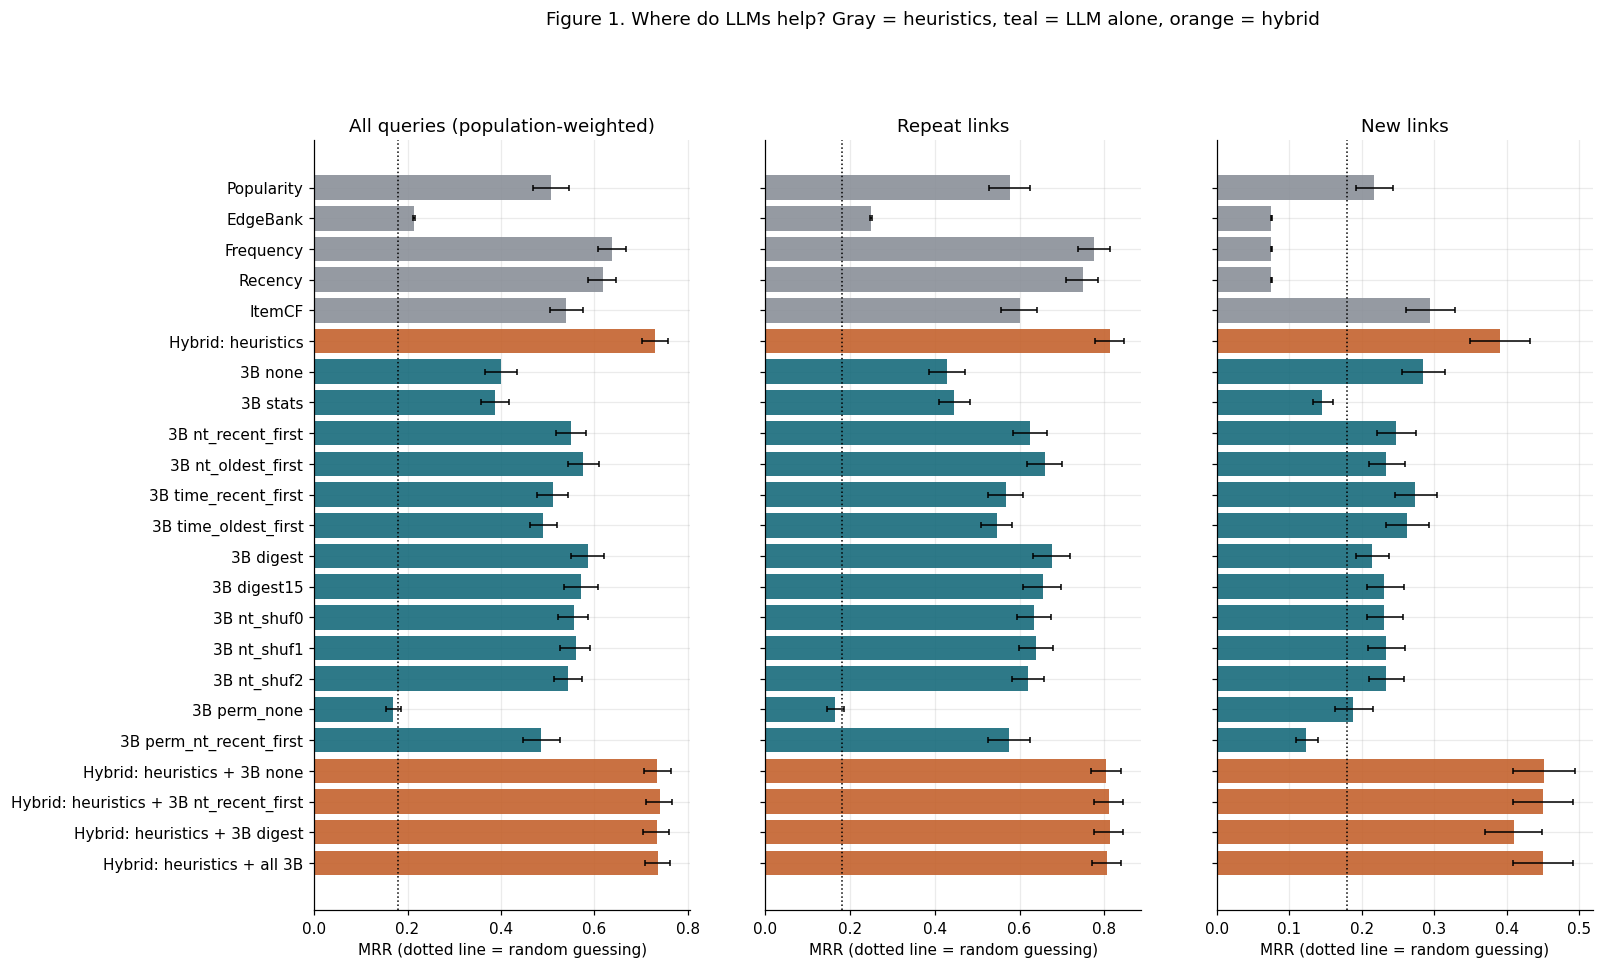

In [ ]:
# Figure 1: main results, three panels (population-weighted, repeat links, new links)
fig, axes = plt.subplots(1, 3, figsize=(15, max(4, .33 * len(main_keys) + 1.5)), sharey=True)
for ax, (st, ttl) in zip(axes, [(ALL, 'All queries (population-weighted)'), (REPS, 'Repeat links'), (NEWS, 'New links')]):
    for yy, k in enumerate(main_keys[::-1]):
        r = summarize(k, st); c = COL['heur'] if k in HEUR else (COL['hyb'] if k.startswith('Hybrid') else COL['llm'])
        ax.barh(yy, r['MRR'], xerr=[[r['MRR'] - r['lo']], [r['hi'] - r['MRR']]], color=c, alpha=.9, error_kw=dict(lw=1, capsize=2))
    ax.axvline(sum(1 / k for k in range(1, N_CAND + 1)) / N_CAND, color='k', ls=':', lw=1); ax.set_title(ttl); ax.set_xlabel('MRR (dotted line = random guessing)')
axes[0].set_yticks(range(len(main_keys))); axes[0].set_yticklabels(main_keys[::-1]); fig.suptitle('Figure 1. Where do LLMs help? Gray = heuristics, teal = LLM alone, orange = hybrid', y=1.01)
savefig(fig, 'F1_main_results')

,status,hypothesis,stratum,diff [95% CI],p_holm,verdict
id,,,,,,
H1,confirmatory (pilot),history helps (events vs no history),all,"+0.150 [+0.108, +0.189]",0.001200,A better
H1n,confirmatory (pilot),history helps on NEW links,new,"-0.037 [-0.069, -0.007]",0.131587,no difference detected
H3,confirmatory (pilot),timestamps hurt (no-timestamp vs timestamped),all,"+0.040 [+0.017, +0.064]",0.007199,A better
H4a,exploratory,new links: LLM vs popularity,new,"+0.030 [-0.008, +0.069]",0.395060,no difference detected
H4b,exploratory,new links: LLM vs item co-occurrence,new,"-0.047 [-0.085, -0.009]",0.131587,no difference detected
H4c,confirmatory (pilot),repeat links: LLM vs frequency,repeat,"-0.151 [-0.192, -0.110]",0.001200,B better
H5,confirmatory (pilot),hybrid beats the best heuristic model (all),all,"+0.010 [-0.004, +0.023]",0.395060,no difference detected
H5n,confirmatory (pilot),hybrid beats heuristic model on NEW links,new,"+0.059 [+0.026, +0.090]",0.003600,A better
H6a,exploratory,compression only: digest15 vs raw events (same...,all,"+0.021 [-0.003, +0.045]",0.304770,no difference detected


H2: does the ORDER of the history matter? (equivalence test, margin +-0.03 MRR)


,format,stratum,diff,CI90,margin,equivalent
0,nt,all,-0.025269,"[-0.042, -0.009]",0.03,False
1,nt,repeat,-0.034670,"[-0.055, -0.014]",0.03,False
2,nt,new,0.013189,"[+0.003, +0.024]",0.03,True
3,time,all,0.019789,"[-0.001, +0.042]",0.03,False
4,time,repeat,0.021649,"[-0.005, +0.049]",0.03,False
5,time,new,0.012178,"[-0.002, +0.027]",0.03,True
6,nt,all (recent vs shuffled seed 0),-0.004936,"[-0.020, +0.010]",0.03,True
7,nt,all (recent vs shuffled seed 1),-0.009090,"[-0.025, +0.006]",0.03,True


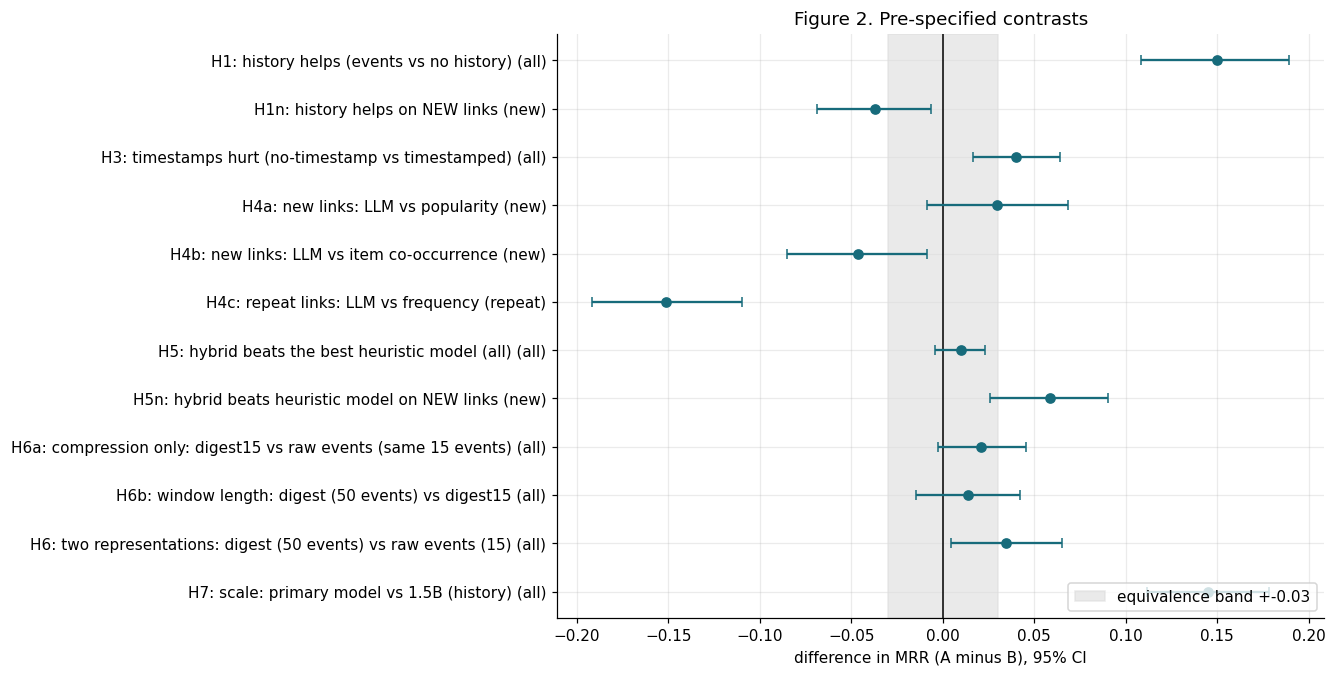

In [ ]:
# Table 3 + Figure 2: pre-specified contrasts (fixed from the validation pilot), Holm-corrected for the whole family
tests = []   # (id, statement, A, B, stratum)
def add(i, text, a, b, st=ALL):
    if have(a, b): tests.append((i, text, a, b, st))
if PL:
    P = lambda c: f'{PL} {c}'
    add('H1', 'history helps (events vs no history)', P('nt_recent_first'), P('none'))
    add('H1n', 'history helps on NEW links', P('nt_recent_first'), P('none'), NEWS)
    add('H3', 'timestamps hurt (no-timestamp vs timestamped)', P('nt_recent_first'), P('time_recent_first'))
    add('H4a', 'new links: LLM vs popularity', P('nt_recent_first'), 'Popularity', NEWS)
    add('H4b', 'new links: LLM vs item co-occurrence', P('nt_recent_first'), 'ItemCF', NEWS)
    add('H4c', 'repeat links: LLM vs frequency', P('nt_recent_first'), 'Frequency', REPS)
    add('H5', 'hybrid beats the best heuristic model (all)', f'Hybrid: heuristics + {P("nt_recent_first")}', 'Hybrid: heuristics')
    add('H5n', 'hybrid beats heuristic model on NEW links', f'Hybrid: heuristics + {P("nt_recent_first")}', 'Hybrid: heuristics', NEWS)
    add('H6a', 'compression only: digest15 vs raw events (same 15 events)', P('digest15'), P('nt_recent_first'))
    add('H6b', 'window length: digest (50 events) vs digest15', P('digest'), P('digest15'))
    add('H6', 'two representations: digest (50 events) vs raw events (15)', P('digest'), P('nt_recent_first'))
    if '1.5B' in LABELS and PL != '1.5B': add('H7', 'scale: primary model vs 1.5B (history)', P('nt_recent_first'), '1.5B nt_recent_first')
CONFIRM = {'H1', 'H1n', 'H3', 'H4c', 'H5', 'H5n', 'H7'}      # hypotheses fixed from the validation pilot; everything else is exploratory (new baselines, new formats, added controls)
rows = []
for i, text, a, b, st in tests:
    r = paired(a, b, st); rows.append(dict(id=i, status='confirmatory (pilot)' if i in CONFIRM else 'exploratory', hypothesis=text, A=a, B=b, stratum={ALL: 'all', REPS: 'repeat', NEWS: 'new'}[st], diff=r['diff'], lo=r['lo'], hi=r['hi'], p=r['p']))
t3 = pd.DataFrame(rows)
if len(t3):
    t3['p_holm'] = holm(t3['p'].values); t3['verdict'] = np.where(t3['p_holm'] < .05, np.where(t3['diff'] > 0, 'A better', 'B better'), 'no difference detected')
    t3['diff [95% CI]'] = t3.apply(lambda r: f"{r['diff']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]", axis=1)
# H2 is an equivalence claim (order does not matter), tested with TOST
eq_rows = []
for fm in ('nt', 'time'):
    a, b = f'{PL} {fm}_recent_first', f'{PL} {fm}_oldest_first'
    if PL and have(a, b):
        for st in (ALL, REPS, NEWS):
            r = equivalent(a, b, stratum=st); eq_rows.append(dict(format=fm, stratum={ALL: 'all', REPS: 'repeat', NEWS: 'new'}[st], diff=r['diff'], CI90=f"[{r['lo90']:+.3f}, {r['hi90']:+.3f}]", margin=EQ_MARGIN, equivalent=r['equivalent']))
for fm in ('nt', 'time'):
    for sd in range(2):
        a, b = f'{PL} {fm}_recent_first', f'{PL} {fm}_shuf{sd}'
        if PL and have(a, b): r = equivalent(a, b); eq_rows.append(dict(format=fm, stratum=f'all (recent vs shuffled seed {sd})', diff=r['diff'], CI90=f"[{r['lo90']:+.3f}, {r['hi90']:+.3f}]", margin=EQ_MARGIN, equivalent=r['equivalent']))
t3b = pd.DataFrame(eq_rows)
display(save_table(t3.set_index('id')[['status', 'hypothesis', 'stratum', 'diff [95% CI]', 'p_holm', 'verdict']] if len(t3) else t3, 'T3_prespecified_contrasts'))
print('H2: does the ORDER of the history matter? (equivalence test, margin +-%.2f MRR)' % EQ_MARGIN); display(save_table(t3b, 'T3b_order_equivalence'))
if len(t3):
    fig, ax = plt.subplots(figsize=(9, .45 * len(t3) + 1.5)); y = np.arange(len(t3))[::-1]
    ax.axvspan(-EQ_MARGIN, EQ_MARGIN, color='#ddd', alpha=.6, label=f'equivalence band +-{EQ_MARGIN}'); ax.axvline(0, color='k', lw=1)
    ax.errorbar(t3['diff'], y, xerr=[t3['diff'] - t3['lo'], t3['hi'] - t3['diff']], fmt='o', color=COL['llm'], capsize=3)
    ax.set_yticks(y); ax.set_yticklabels([f"{r.id}: {r.hypothesis} ({r.stratum})" for r in t3.itertuples()]); ax.set_xlabel('difference in MRR (A minus B), 95% CI'); ax.legend(loc='lower right')
    ax.set_title('Figure 2. Pre-specified contrasts'); savefig(fig, 'F2_contrasts')

MRR all  MRR repeat   MRR new
model  condition                                           
0.5B   none                  0.226020    0.227812  0.218689
       digest                0.401532    0.445252  0.222686
       nt_recent_first       0.365810    0.405699  0.202639
       nt_oldest_first       0.367042    0.409406  0.193745
       time_recent_first     0.378399    0.420293  0.207022
1.5B   none                  0.321078    0.341058  0.239346
       digest                0.428973    0.475830  0.237294
       nt_recent_first       0.405494    0.445974  0.239901
       nt_oldest_first       0.403156    0.440105  0.252006
       time_recent_first     0.379556    0.408750  0.260132
3B     none                  0.400827    0.429427  0.283833
       stats                 0.386694    0.445582  0.145799
       digest                0.585266    0.676108  0.213656
       nt_recent_first       0.550497    0.624709  0.246912
       nt_oldest_first       0.575765    0.659380  0.233723
       nt_shuf0              0.555433    0.634880  0.230437
       nt_shuf1              0.559586    0.639437  0.232942
       time_recent_first     0.510383    0.568178  0.273960
       time_oldest_first     0.490594    0.546529  0.261781
       perm_none             0.169725    0.165155  0.188421
       perm_nt_recent_first  0.486274    0.574927  0.123619
Phi3.5 none                  0.360049    0.378977  0.282623
       digest                0.489444    0.548630  0.247330
       nt_recent_first       0.392375    0.421441  0.273476
       nt_oldest_first       0.393161    0.420187  0.282607

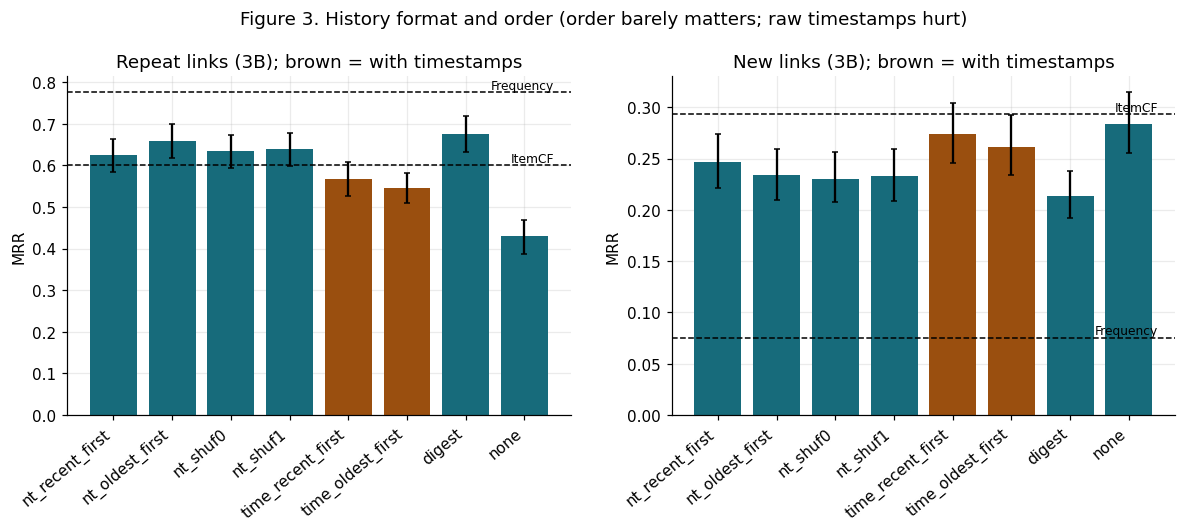

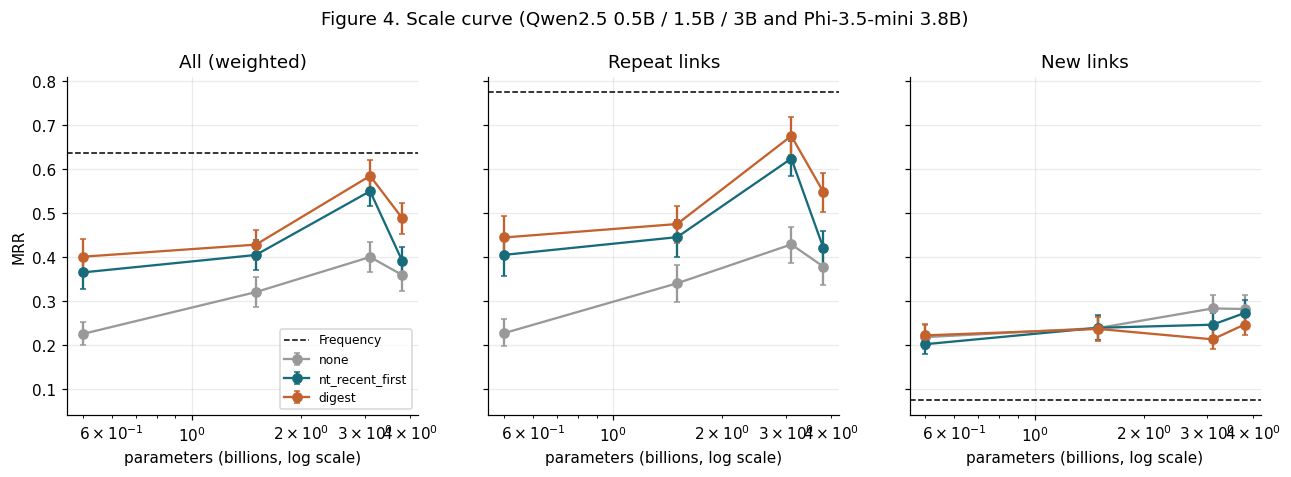

In [ ]:
# Table 4 + Figure 3: format x order grid for every model, Figure 4: scale curve
def cell(label, c, st=ALL): return summarize(f'{label} {c}', st)['MRR'] if have(f'{label} {c}') else np.nan
grid = []
for L in LABELS:
    for c in ['none', 'stats', 'digest', 'nt_recent_first', 'nt_oldest_first', 'nt_shuf0', 'nt_shuf1', 'time_recent_first', 'time_oldest_first', 'perm_none', 'perm_nt_recent_first']:
        if have(f'{L} {c}'): grid.append(dict(model=L, condition=c, **{'MRR all': cell(L, c, ALL), 'MRR repeat': cell(L, c, REPS), 'MRR new': cell(L, c, NEWS)}))
t4 = pd.DataFrame(grid); display(save_table(t4.set_index(['model', 'condition']), 'T4_all_conditions'))
if PL:
    conds = [c for c in ['nt_recent_first', 'nt_oldest_first', 'nt_shuf0', 'nt_shuf1', 'time_recent_first', 'time_oldest_first', 'time_shuf0', 'digest', 'none'] if have(f'{PL} {c}')]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
    for ax, st, ttl in zip(axes, (REPS, NEWS), ('Repeat links', 'New links')):
        vals = [summarize(f'{PL} {c}', st) for c in conds]
        ax.bar(range(len(conds)), [v['MRR'] for v in vals], yerr=[[v['MRR'] - v['lo'] for v in vals], [v['hi'] - v['MRR'] for v in vals]], color=[COL['neg'] if c.startswith('time') else COL['llm'] for c in conds], capsize=2)
        for hb, hn in (('Frequency', 'Frequency'), ('ItemCF', 'ItemCF')): ax.axhline(summarize(hb, st)['MRR'], ls='--', lw=1, color='k'); ax.text(len(conds) - .5, summarize(hb, st)['MRR'], hn, ha='right', va='bottom', fontsize=8)
        ax.set_xticks(range(len(conds))); ax.set_xticklabels(conds, rotation=40, ha='right'); ax.set_title(f'{ttl} ({PL}); brown = with timestamps'); ax.set_ylabel('MRR')
    fig.suptitle('Figure 3. History format and order (order barely matters; raw timestamps hurt)', y=1.03); savefig(fig, 'F3_format_order')
if len(LABELS) > 1:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
    for ax, st, ttl in zip(axes, (ALL, REPS, NEWS), ('All (weighted)', 'Repeat links', 'New links')):
        for c, col in (('none', '#999'), ('nt_recent_first', COL['llm']), ('digest', COL['hyb'])):
            xs = [(MODEL_SIZE_B[L], summarize(f'{L} {c}', st)) for L in LABELS if have(f'{L} {c}')]
            if xs: ax.errorbar([a for a, _ in xs], [b['MRR'] for _, b in xs], yerr=[[b['MRR'] - b['lo'] for _, b in xs], [b['hi'] - b['MRR'] for _, b in xs]], marker='o', label=c, color=col, capsize=2)
        ax.axhline(summarize('Frequency', st)['MRR'], ls='--', color='k', lw=1, label='Frequency'); ax.set_xscale('log'); ax.set_xlabel('parameters (billions, log scale)'); ax.set_title(ttl)
    axes[0].set_ylabel('MRR'); axes[0].legend(fontsize=8); fig.suptitle('Figure 4. Scale curve (Qwen2.5 0.5B / 1.5B / 3B and Phi-3.5-mini 3.8B)', y=1.03); savefig(fig, 'F4_scale')

MRR  \
model                                   stratum                         
Hybrid: heuristics                      all      0.730 [0.701, 0.757]   
                                        repeat   0.812 [0.778, 0.845]   
                                        new      0.391 [0.350, 0.432]   
Hybrid: heuristics + 3B none            all      0.735 [0.705, 0.763]   
                                        repeat   0.804 [0.769, 0.838]   
                                        new      0.452 [0.409, 0.494]   
Hybrid: heuristics + 3B nt_recent_first all      0.739 [0.710, 0.767]   
                                        repeat   0.810 [0.776, 0.843]   
                                        new      0.450 [0.408, 0.491]   
Hybrid: heuristics + 3B digest          all      0.733 [0.704, 0.761]   
                                        repeat   0.812 [0.777, 0.845]   
                                        new      0.410 [0.369, 0.448]   
Hybrid: heuristics + all 3B             all      0.735 [0.707, 0.762]   
                                        repeat   0.805 [0.771, 0.839]   
                                        new      0.449 [0.408, 0.491]   
Xfit: heuristics                        all      0.730 [0.700, 0.759]   
                                        repeat   0.804 [0.769, 0.838]   
                                        new      0.427 [0.385, 0.468]   
Xfit: heuristics + 3B none              all      0.732 [0.703, 0.761]   
                                        repeat   0.798 [0.762, 0.834]   
                                        new      0.462 [0.421, 0.504]   
Xfit: heuristics + 3B nt_recent_first   all      0.738 [0.709, 0.767]   
                                        repeat   0.805 [0.771, 0.839]   
                                        new      0.465 [0.423, 0.507]   
Xfit: heuristics + 3B digest            all      0.735 [0.704, 0.764]   
                                        repeat   0.804 [0.767, 0.839]   
                                        new      0.453 [0.412, 0.493]   

                                                    gain over heuristics  
model                                   stratum                           
Hybrid: heuristics                      all                            -  
                                        repeat                         -  
                                        new                            -  
Hybrid: heuristics + 3B none            all      +0.005 [-0.005, +0.016]  
                                        repeat   -0.008 [-0.020, +0.003]  
                                        new      +0.061 [+0.035, +0.088]  
Hybrid: heuristics + 3B nt_recent_first all      +0.010 [-0.004, +0.023]  
                                        repeat   -0.002 [-0.018, +0.014]  
                                        new      +0.059 [+0.026, +0.090]  
Hybrid: heuristics + 3B digest          all      +0.004 [-0.011, +0.018]  
                                        repeat   -0.000 [-0.017, +0.016]  
                                        new      +0.019 [-0.007, +0.046]  
Hybrid: heuristics + all 3B             all      +0.006 [-0.010, +0.021]  
                                        repeat   -0.007 [-0.026, +0.012]  
                                        new      +0.058 [+0.026, +0.091]  
Xfit: heuristics                        all                            -  
                                        repeat                         -  
                                        new                            -  
Xfit: heuristics + 3B none              all      +0.002 [-0.007, +0.012]  
                                        repeat   -0.006 [-0.016, +0.004]  
                                        new      +0.035 [+0.012, +0.061]  
Xfit: heuristics + 3B nt_recent_first   all      +0.008 [-0.003, +0.018]  
                                        repeat   +0.001 [-0.011, +0.012]  
                                        new      +0.037 [+0.011, +0.064] 

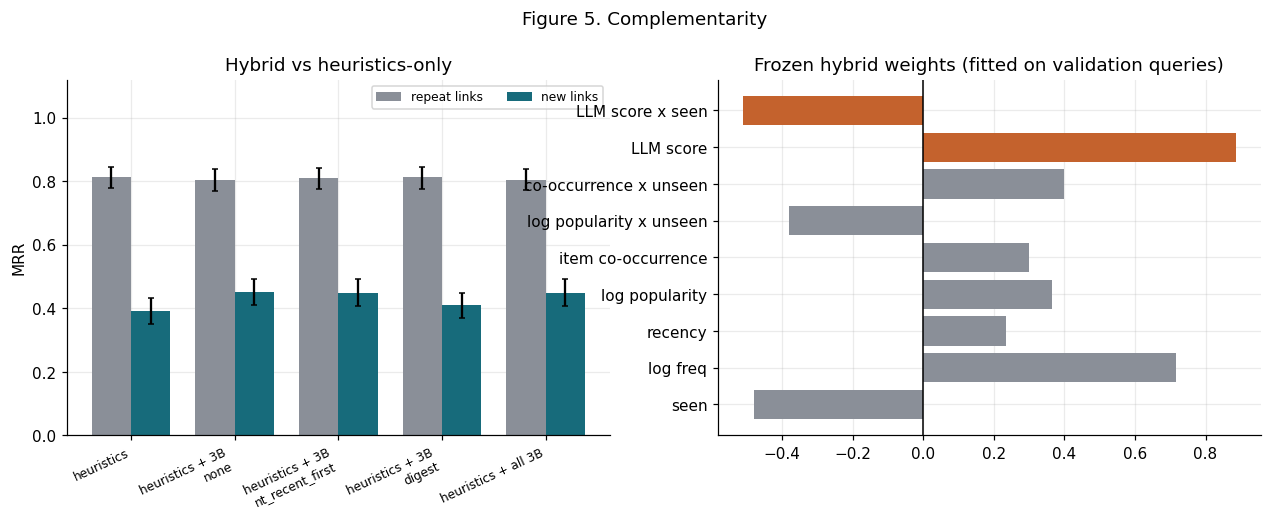

In [ ]:
# Table 5 + Figure 5: is the LLM complementary to heuristics? (hybrid) and what does the hybrid weigh?
hy = []
for k in STACKS + XFITS:
    for st, nm in ((ALL, 'all'), (REPS, 'repeat'), (NEWS, 'new')):
        r = summarize(k, st); d = paired(k, 'Hybrid: heuristics' if k.startswith('Hybrid') else 'Xfit: heuristics', st) if k not in ('Hybrid: heuristics', 'Xfit: heuristics') else None
        hy.append(dict(model=k, stratum=nm, MRR=fmt(r), **{'gain over heuristics': f"{d['diff']:+.3f} [{d['lo']:+.3f}, {d['hi']:+.3f}]" if d else '-'}))
t5 = pd.DataFrame(hy); display(save_table(t5.set_index(['model', 'stratum']), 'T5_hybrid'))
bestk = f'Hybrid: heuristics + {PL} nt_recent_first' if f'Hybrid: heuristics + {PL} nt_recent_first' in S else (STACKS[-1] if len(STACKS) > 1 else None)
if bestk:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    names = ['Hybrid: heuristics'] + [k for k in STACKS[1:]]
    for k_i, k in enumerate(names):
        for s_i, (st, col) in enumerate(((REPS, COL['heur']), (NEWS, COL['llm']))):
            r = summarize(k, st); axes[0].bar(k_i + (s_i - .5) * .38, r['MRR'], .38, yerr=[[r['MRR'] - r['lo']], [r['hi'] - r['MRR']]], color=col, capsize=2, label=('repeat links' if st == REPS else 'new links') if k_i == 0 else None)
    axes[0].set_xticks(range(len(names))); axes[0].set_xticklabels([n.replace('Hybrid: ', '').replace(PL + ' ', PL + '\n') for n in names], rotation=25, ha='right', fontsize=8); axes[0].set_ylabel('MRR'); axes[0].set_ylim(0, 1.12); axes[0].legend(loc='upper right', ncol=2, fontsize=8); axes[0].set_title('Hybrid vs heuristics-only')
    llm_k = tuple(k for k in KEYS_H if bestk.endswith(k))[:1]; w = HYB_W.get(llm_k, np.zeros(len(FEATURE_NAMES) + 2 * len(llm_k))); wn = (FEATURE_NAMES + ['LLM score', 'LLM score x seen'])[:len(w)]
    axes[1].barh(range(len(w)), w, color=[COL['hyb'] if 'LLM' in x else COL['heur'] for x in wn]); axes[1].set_yticks(range(len(w))); axes[1].set_yticklabels(wn); axes[1].axvline(0, color='k', lw=1)
    axes[1].set_title('Frozen hybrid weights (fitted on validation queries)' if FROZEN else 'Hybrid weights (not available)'); fig.suptitle('Figure 5. Complementarity', y=1.03); savefig(fig, 'F5_hybrid')

,hist,active,random
Popularity,0.621,0.633,0.907
Frequency,0.658,0.851,0.840
ItemCF,0.567,0.874,0.948
Hybrid: heuristics,0.754,0.910,0.964
3B none,0.469,0.717,0.728
3B nt_recent_first,0.588,0.869,0.902
3B digest,0.614,0.865,0.866
Hybrid: heuristics + 3B nt_recent_first,0.769,0.909,0.964


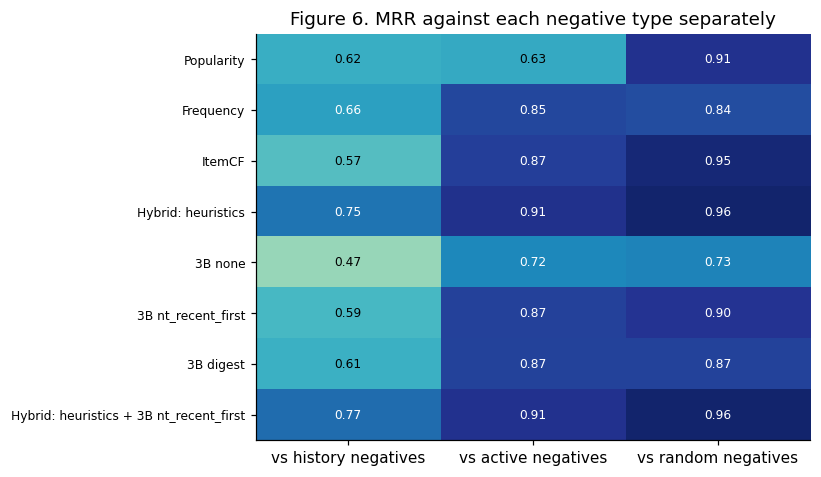

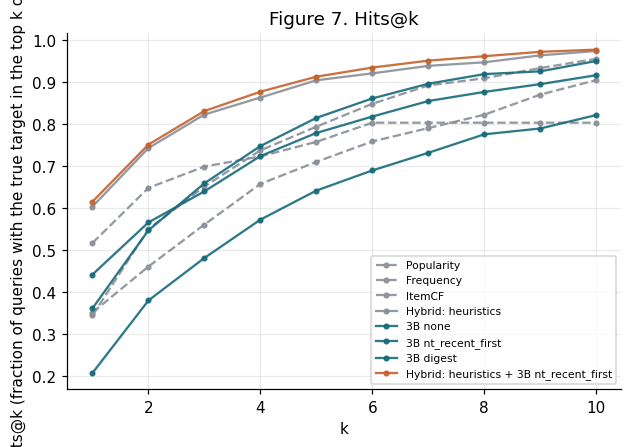

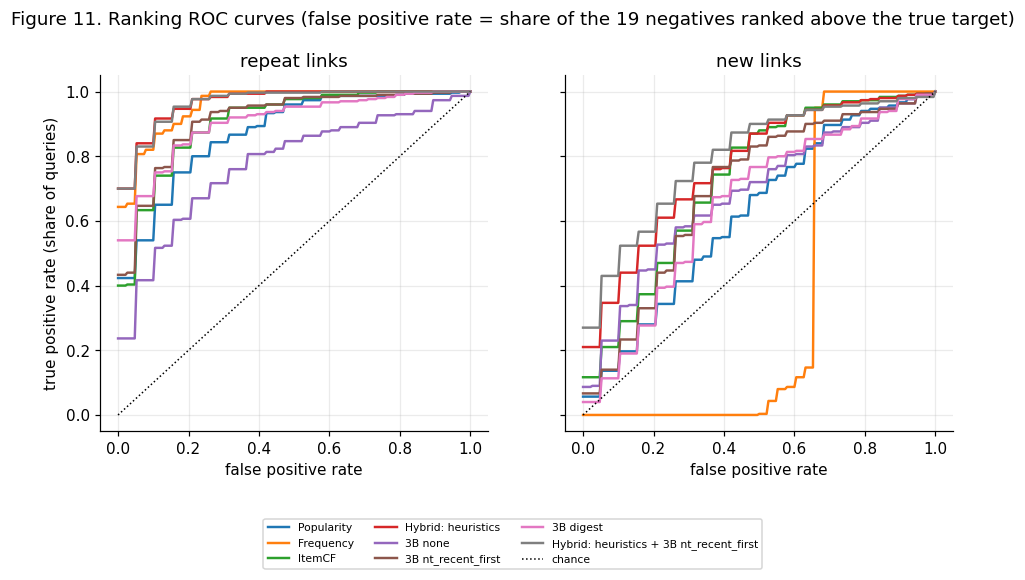

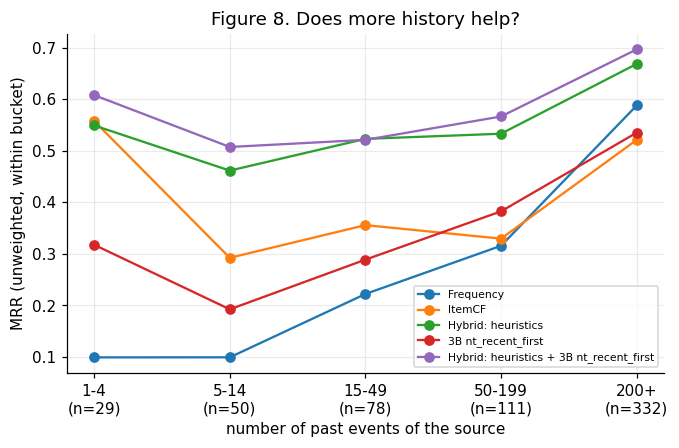

,diff,lo,hi,n
contrast,,,,
first - last,-0.013,-0.063,0.037,58
first - middle,0.019,-0.037,0.078,58
middle - last,-0.032,-0.098,0.041,58


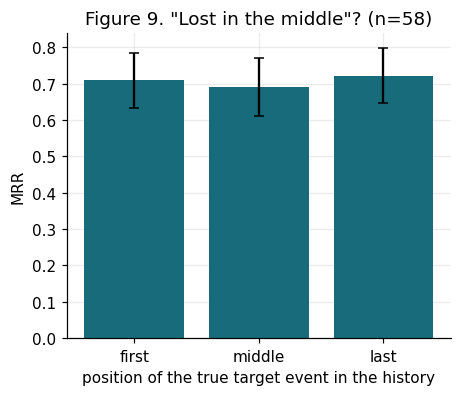

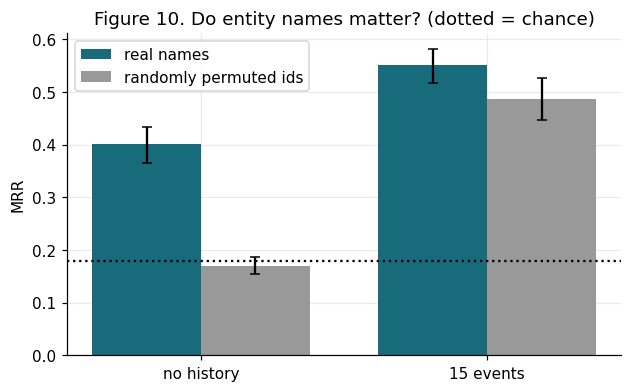

In [ ]:
# Table 6 / Figures 6-9: robustness: negative types, Hits@k, history length, position test, permuted-id control
keys_rb = [k for k in (['Popularity', 'Frequency', 'ItemCF', 'Hybrid: heuristics'] + [f'{PL} none', f'{PL} nt_recent_first', f'{PL} digest'] + ([bestk] if bestk else [])) if k in S]
neg = pd.DataFrame({k: {t: summarize(k, ALL, keep=(t,))['MRR'] for t in ('hist', 'active', 'random')} for k in keys_rb}).T
display(save_table(neg.round(3), 'T6_by_negative_type'))
fig, ax = plt.subplots(figsize=(6.5, .45 * len(keys_rb) + 1.2)); im = ax.imshow(neg.values, cmap='YlGnBu', vmin=.2, vmax=1, aspect='auto')
ax.set_xticks(range(3)); ax.set_xticklabels(['vs history negatives', 'vs active negatives', 'vs random negatives']); ax.set_yticks(range(len(neg))); ax.set_yticklabels(neg.index, fontsize=8)
for (i, j), v in np.ndenumerate(neg.values): ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='w' if v > .65 else 'k')
ax.set_title('Figure 6. MRR against each negative type separately'); ax.grid(False); savefig(fig, 'F6_negative_types')

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for k in keys_rb:
    ax.plot(range(1, 11), [point(HITv(k, kk), ALL) for kk in range(1, 11)], marker='o', ms=3, label=k, color=COL['heur'] if k in HEUR or k == 'Hybrid: heuristics' else (COL['hyb'] if k.startswith('Hybrid') else COL['llm']), alpha=.9, ls='-' if k.startswith('Hybrid') else '--' if k in HEUR else '-')
ax.set_xlabel('k'); ax.set_ylabel('Hits@k (fraction of queries with the true target in the top k of 20)'); ax.legend(fontsize=7); ax.set_title('Figure 7. Hits@k'); savefig(fig, 'F7_hits_at_k')

# Figure 11: ranking ROC curve. For each query, true positive = the true target; false positive rate x = share of the 19 negatives ranked above it.
# The curve is the share of queries whose true target beats all but a fraction x of the negatives; the area under it is the AUC in Table 2 (diagonal = chance).
grid = np.linspace(0, 1, 191); fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, (stt, ttl) in zip(axes, ((REPS, 'repeat links'), (NEWS, 'new links'))):
    for k in keys_rb:
        fpr = 1 - AUCv(k); fpr = fpr[REP] if stt == REPS else fpr[~REP]
        ax.plot(grid, [(fpr <= g + 1e-9).mean() for g in grid], label=k, lw=1.6)
    ax.plot([0, 1], [0, 1], 'k:', lw=1, label='chance'); ax.set_xlabel('false positive rate'); ax.set_title(ttl)
axes[0].set_ylabel('true positive rate (share of queries)'); fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=7, bbox_to_anchor=(.5, -.2)); fig.suptitle('Figure 11. Ranking ROC curves (false positive rate = share of the 19 negatives ranked above the true target)', y=1.02); savefig(fig, 'F11_roc')

edges_b = [1, 5, 15, 50, 200, 10**9]; lab_b = ['1-4', '5-14', '15-49', '50-199', '200+']; bk = np.digitize(N_PAST, edges_b[1:-1]) if False else np.digitize(N_PAST, [5, 15, 50, 200])
fig, ax = plt.subplots(figsize=(7, 4))
for k in [x for x in keys_rb if x in ('Frequency', 'ItemCF', f'{PL} nt_recent_first', 'Hybrid: heuristics', bestk)]:
    r = RRv(k); ax.plot(range(5), [r[bk == b].mean() if (bk == b).sum() else np.nan for b in range(5)], marker='o', label=k)
ax.set_xticks(range(5)); ax.set_xticklabels([f'{l}\n(n={(bk == b).sum()})' for b, l in enumerate(lab_b)]); ax.set_xlabel('number of past events of the source'); ax.set_ylabel('MRR (unweighted, within bucket)'); ax.legend(fontsize=7); ax.set_title('Figure 8. Does more history help?'); savefig(fig, 'F8_history_length')

if PL and all((PL, w) in SPOS for w in ('first', 'middle', 'last')):
    rr_pos = {w: np.array([1 / (1 + ((SPOS[(PL, w)][j] > SPOS[(PL, w)][j][TI[qid]]) & (TYPE[qid] != 0)).sum() + ((SPOS[(PL, w)][j] == SPOS[(PL, w)][j][TI[qid]]) & (TYPE[qid] != 0)).sum() / 2) for j, qid in enumerate(POS_IDS)]) for w in ('first', 'middle', 'last')}
    g = np.random.default_rng(3); pos_rows = []
    for a, b in (('first', 'last'), ('first', 'middle'), ('middle', 'last')):
        d = rr_pos[a] - rr_pos[b]; bd = d[g.integers(0, len(d), (BOOT_B, len(d)))].mean(1); pos_rows.append(dict(contrast=f'{a} - {b}', diff=d.mean(), lo=np.percentile(bd, 2.5), hi=np.percentile(bd, 97.5), n=len(d)))
    display(save_table(pd.DataFrame(pos_rows).set_index('contrast').round(3), 'T7_position_test'))
    fig, ax = plt.subplots(figsize=(4.5, 3.6)); ax.bar(range(3), [rr_pos[w].mean() for w in ('first', 'middle', 'last')], yerr=[1.96 * rr_pos[w].std() / np.sqrt(len(rr_pos[w])) for w in ('first', 'middle', 'last')], color=COL['llm'], capsize=3)
    ax.set_xticks(range(3)); ax.set_xticklabels(['first', 'middle', 'last']); ax.set_xlabel('position of the true target event in the history'); ax.set_ylabel('MRR'); ax.set_title(f'Figure 9. "Lost in the middle"? (n={len(POS_IDS)})'); savefig(fig, 'F9_position')

ctrl = [(a, b) for a, b in (('none', 'perm_none'), ('nt_recent_first', 'perm_nt_recent_first')) if PL and have(f'{PL} {a}', f'{PL} {b}')]
if ctrl:
    fig, ax = plt.subplots(figsize=(6.5, 3.8)); w = .38
    for j, (a, b) in enumerate(ctrl):
        for s_i, (c, col, lab) in enumerate(((a, COL['llm'], 'real names'), (b, '#999', 'randomly permuted ids'))):
            r = summarize(f'{PL} {c}'); ax.bar(j + (s_i - .5) * w, r['MRR'], w, yerr=[[r['MRR'] - r['lo']], [r['hi'] - r['MRR']]], color=col, capsize=3, label=lab if j == 0 else None)
    ax.axhline(sum(1 / k for k in range(1, N_CAND + 1)) / N_CAND, color='k', ls=':'); ax.set_xticks(range(len(ctrl))); ax.set_xticklabels(['no history' if a == 'none' else '15 events' for a, _ in ctrl]); ax.set_ylabel('MRR'); ax.legend()
    ax.set_title('Figure 10. Do entity names matter? (dotted = chance)'); savefig(fig, 'F10_names_vs_permuted_ids')

In [ ]:
# 13. auto-written results summary + zip of everything (download it, and keep the Drive folder)
def g_(name, st=ALL): return summarize(name, st)['MRR'] if name in S else float('nan')
L = []
L.append(f'# Results summary ({DATASET}, {EVAL_SPLIT} split, {NQ} queries: {REP.sum()} repeat / {(~REP).sum()} new; population share of repeat links {P_REP:.2f})\n')
L.append('Population-weighted MRR (all): ' + ', '.join(f'{k} {g_(k):.3f}' for k in HEUR + ['Hybrid: heuristics'] + [k for k in S if k.startswith(PL + " ")][:6]))
for i, text, a, b, st in tests:
    r = paired(a, b, st); L.append(f'- {i} ({text}; {st}): {r["diff"]:+.3f} MRR, 95% CI [{r["lo"]:+.3f}, {r["hi"]:+.3f}]')
for r in eq_rows[:4]: L.append(f"- order equivalence ({r['format']}, {r['stratum']}): diff {r['diff']:+.3f}, 90% CI {r['CI90']}, equivalent within +-{EQ_MARGIN}: {r['equivalent']}")
L.append('\nRun time per condition (minutes): ' + ', '.join(f"{r['model']}/{r['cond']} {r['minutes']}" for r in RUNLOG))
open(f'{OUT_DIR}/RESULTS_SUMMARY.md', 'w').write('\n'.join(L)); print('\n'.join(L))
save_bundle()
shutil.make_archive(f'{OUT_DIR}/results_{EVAL_SPLIT}', 'zip', OUT_DIR, 'figs'); shutil.make_archive(f'{OUT_DIR}/tables_{EVAL_SPLIT}', 'zip', OUT_DIR, 'tables')
print('\nDONE. Figures: ', OUT_DIR + '/figs', '| tables:', OUT_DIR + '/tables')
try:
    from google.colab import files; files.download(f'{OUT_DIR}/results_{EVAL_SPLIT}.zip'); files.download(f'{OUT_DIR}/tables_{EVAL_SPLIT}.zip')
except Exception as e: print('(download manually from Drive)', e)

# Results summary (ICEWS1819, test split, 600 queries: 300 repeat / 300 new; population share of repeat links 0.80)

Population-weighted MRR (all): Popularity 0.507, EdgeBank 0.214, Frequency 0.638, Recency 0.618, ItemCF 0.540, Hybrid: heuristics 0.730, 3B none 0.401, 3B stats 0.387, 3B nt_recent_first 0.550, 3B nt_oldest_first 0.576, 3B time_recent_first 0.510, 3B time_oldest_first 0.491
- H1 (history helps (events vs no history); all): +0.150 MRR, 95% CI [+0.108, +0.189]
- H1n (history helps on NEW links; new): -0.037 MRR, 95% CI [-0.069, -0.007]
- H3 (timestamps hurt (no-timestamp vs timestamped); all): +0.040 MRR, 95% CI [+0.017, +0.064]
- H4a (new links: LLM vs popularity; new): +0.030 MRR, 95% CI [-0.008, +0.069]
- H4b (new links: LLM vs item co-occurrence; new): -0.047 MRR, 95% CI [-0.085, -0.009]
- H4c (repeat links: LLM vs frequency; rep): -0.151 MRR, 95% CI [-0.192, -0.110]
- H5 (hybrid beats the best heuristic model (all); all): +0.010 MRR, 95% CI [-0.004, +0.023]
- H5n (hyb

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files
import os

# Define paths for the figures folder
figs_dir = f'{OUT_DIR}/figs'
zip_output_path = f'{OUT_DIR}/figure_outputs_download'

if os.path.exists(figs_dir):
    # Compress the figures directory into a zip archive
    shutil.make_archive(zip_output_path, 'zip', figs_dir)
    print(f'Archive created successfully: {zip_output_path}.zip')

    # Trigger direct browser download
    files.download(f'{zip_output_path}.zip')
else:
    print(f'Figures directory not found at: {figs_dir}')

Archive created successfully: /content/drive/MyDrive/link_pred_runs/final_v1/figure_outputs_download.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files
import os

# Define paths based on configuration
figs_dir = f'{OUT_DIR}/figs'
zip_output_path = f'{OUT_DIR}/all_figure_outputs'

if os.path.exists(figs_dir):
    # Compress the figures directory into a zip archive
    shutil.make_archive(zip_output_path, 'zip', figs_dir)
    print(f'Archive created successfully: {zip_output_path}.zip')

    # Download the zipped file to your local machine
    files.download(f'{zip_output_path}.zip')
else:
    print(f'Figures directory not found at: {figs_dir}')

Archive created successfully: /content/drive/MyDrive/link_pred_runs/final_v1/all_figure_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. How to turn these outputs into the paper
| Paper section | Use |
|---|---|
| Abstract / intro claim | Q: where do LLMs help temporal link prediction, and does the history format matter? A: use the sign and size of H1, H3, H4, H5, H6 from Table 3, and the order-equivalence result (T3b). Write only what the tables show. |
| Method | Table 1 (protocol), the 4 candidate types, repeat/new strata and population weighting, the prompt formats (print one prompt per format from cell 6), the integrity audit (T0). |
| Results 1: strong baselines | Table 2 + Figure 1 + Figure 6 (by negative type) + Figure 7 (Hits@k). |
| Results 2: format, order, timestamps | Table 3b, Table 4, Figures 2 and 3, Figure 9 (position). |
| Results 3: scale and family | Figure 4 (0.5B, 1.5B, 3B, Phi-3.5). |
| Results 4: hybrid | Table 5, Figure 5 (where the LLM weight is used). |
| Controls | Figure 10 (names vs permuted ids), T0 audit, fast-vs-slow scorer check printed when each model loads. |
**Honest limitations to state:** one dataset (ICEWS1819), sampled-candidate evaluation (20 candidates, not full ranking), small open models, prompts of one wording per format, test queries are a stratified sample, results of the hybrid come from cross-fitting inside the test queries (no separate tuning split), the pre-specified hypotheses came from a 500-query validation pilot, entity names may be partly known to pretrained models (contamination is not ruled out; the permuted-id control only shows names matter, not why).
**If a result goes the other way than the pilot, report it as it is.** The audit, equivalence margin and hypotheses were fixed before this run.